# Q2D | Train Linear Regression

# Imports

In [1]:
from itertools import product

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from Q2.consts import *

from utils import read_csv_to_df
from utils.scoring.standard_error import standard_error

from Q2.utils import (
	chronological_split,
	Q2_CROSS_VALIDATION,
	Q2_PLOTTING,
	Q2_FEATURES,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

## Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


The same chronological split as Q2B and Q2C. `test_df` is not used again in this notebook.

## Attributes

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


The same 11 attributes as Q2C: 4 continuous, 3 binary and 4 multi-level codes. `ID`, `Date`, `Casual` and `Registered` are left out, as concluded in Q2B.

## Folds

In [5]:
FOLDS = Q2_CROSS_VALIDATION.make_time_folds(
	data=train_df,
	date_col="Date",
	n_splits=CV_SPLITS,
	test_size=CV_TEST_SIZE
)
# mean validation rows / training rows of the folds, used by every SE below
TEST_TRAIN_RATIO = Q2_CROSS_VALIDATION.test_train_ratio(folds=FOLDS)
print(len(FOLDS))

pd.DataFrame({
	"train rows": [len(train_index) for train_index, _ in FOLDS],
	"validation rows": [len(val_index) for _, val_index in FOLDS],
	"validation first date": [f"{train_df.loc[val_index, 'Date'].min():%Y-%m-%d}" for _, val_index in FOLDS],
	"validation last date": [f"{train_df.loc[val_index, 'Date'].max():%Y-%m-%d}" for _, val_index in FOLDS],
}, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

6


,train rows,validation rows,validation first date,validation last date
fold,,,,
1,398,31,2012-02-03,2012-03-04
2,429,31,2012-03-05,2012-04-04
3,460,31,2012-04-05,2012-05-05
4,491,31,2012-05-06,2012-06-05
5,522,31,2012-06-06,2012-07-06
6,553,31,2012-07-07,2012-08-06


# Method
**Cross-validation.** Every model is scored on 6 time-ordered folds. Each fold trains on every training day before its validation block and validates on the next 31 days. The training side grows from fold to fold (398 rows in the first fold, 553 in the last), and the last validation block ends on the last training day. The folds are built once (`FOLDS`) and reused by every experiment, so every model is validated on exactly the same days and any two models can be compared fold by fold. No attribute has a missing value, so no row is dropped.

- **Why time-ordered.** Q2C scored its interventions on shuffled folds, where a validation day usually has training days on both sides of it. Those scores describe days inside the training period. Here the score is meant to predict performance on the test set, which holds the days after the training period, so every fold validates on days that come after all of its training days.
- **Why validation starts in 2012.** A fold that trains on 2011 only sees a single value of `Year`, so it cannot learn anything from that attribute. The first validation block starts on 2012-02-03, so even the first fold trains on 33 days of 2012.
- **Two limits.** 6 folds give only 6 differences per comparison, so the noise band of the 1 SE rule below is estimated from few values and the rule is coarser. And each fold looks at most 31 days past its training rows, while the test set covers 147 days, so the validation RMSE can still be optimistic for the later test days.

**Metric.** The metric is RMSE (root mean squared error), reported for the validation rows and for the training rows of each fold. It is in the same units as Rentals (rentals per day), it penalizes large misses more than small ones, and it matches the squared error that linear regression minimizes.

**Noise rule.** A lower mean RMSE is not automatically a real improvement, because the score moves from fold to fold. Each experiment is compared with a baseline through the 6 per-fold differences in validation RMSE (experiment minus baseline). SE is the standard error of the mean of those differences, corrected for the folds sharing most of their training rows. The correction uses the folds' mean ratio of validation rows to training rows (`TEST_TRAIN_RATIO`). The rule used throughout:

- **really better:** the mean change is below -1 SE.
- **really worse:** the mean change is above +1 SE.
- **noise:** anything in between. The simpler model is kept.

**Charts.** Every single experiment has one chart. Left: RMSE on every fold, dots for validation and x marks for training, with the means in the legend. Right: the per-fold change in validation RMSE against the baseline (green is better, red is worse), the mean change as a dashed line, and the ±1 SE noise band in gray. The folds run left to right in time order, and each one is labelled with the first date of its validation block. The title gives the verdict. The one exception is inside a selection step, where every candidate in the pool is scored: only the accepted change is charted, and the step's table covers the rest.

# Dummy Regressor
A baseline that ignores the attributes and always predicts the mean Rentals of its training rows. Any real model has to beat it.

In [6]:
dummy_val_scores, dummy_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=DummyRegressor(strategy="mean"),
	folds=FOLDS,
	target=TARGET
)

# Closed Form Linear Regression
`LinearRegression` on the 11 raw attributes, with the multi-level codes (`Season`, `Month`, `Weekday`, `Weather`) entered as numbers. It solves the least squares problem in closed form: one direct solve, with no iterations and no learning rate. scikit-learn computes that solution with an SVD-based solver.

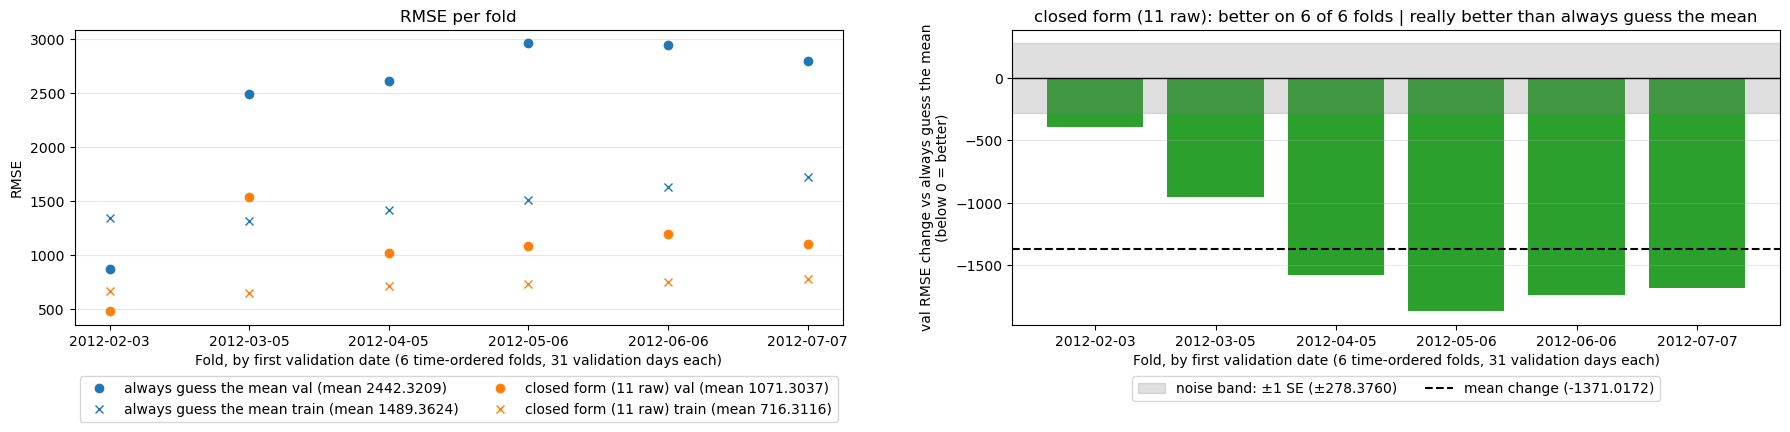

In [7]:
closedform_lr_val_scores, closedform_lr_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=ATTRIBUTES,
	estimator=LinearRegression(),
	folds=FOLDS,
	target=TARGET
)

Q2_PLOTTING.cv_fold_scores(
	baseline=(dummy_val_scores, dummy_train_scores),
	compare=(closedform_lr_val_scores, closedform_lr_train_scores),
	baseline_name="always guess the mean",
	compare_name="closed form (11 raw)",
	folds=FOLDS,
	dates=train_df["Date"],
)

**Closed form against the baseline.** Always guessing the mean scores a validation RMSE of 2442.3209. Closed form linear regression on the 11 raw attributes scores 1071.3037, a change of -1371.0172 (SE 278.3760), and is better on all 6 folds. Its training RMSE (716.3116) is well below its validation RMSE, so it fits the days it trained on better than the days that follow. The baseline has the same gap (1489.3624 against 2442.3209), so much of it comes from the validation days sitting at a different Rentals level than the earlier training days, which is what time-ordered folds are meant to show. 1071.3037 is the score the step-by-step selection starts from.

# Candidate Changes
Q1D tested imputing its missing rows at this point. This dataset has no missing values, so that step has no equivalent here. In its place, this section lists the changes to the 11 raw attributes that Q2C's findings suggest. They are the candidates for the step-by-step selection in the next section.

**Drops.** The attribute is removed from the model.

| Candidate | Why it is a candidate (from Q2C) |
|---|---|
| drop Temp | redundant with `FeelsLike` (r = 0.997) |
| drop Season | redundant with `Month` (r = 0.862) |
| drop Weekday | no relationship with Rentals |
| drop IsHoliday | no relationship with Rentals |
| drop IsWorkday | no relationship with Rentals, and fully determined by `Weekday` and `IsHoliday` |
| drop Year | checks that `Year` should stay |

**Shapes.** The raw column is replaced by new columns.

| Candidate | New columns | Replaces |
|---|---|---|
| FeelsLike flat top | flat top at 0.57 | raw `FeelsLike` |
| Temp flat top | flat top at 0.57 | raw `Temp` |
| Humidity hinge | hinge at 0.75 | raw `Humidity` |
| Month sine / cosine | sine, cosine | the `Month` code |
| Month one-hot | months 2 to 12 (11 columns) | the `Month` code |
| Season one-hot | seasons 2 to 4 (3 columns) | the `Season` code |
| Weather one-hot | levels 2 and 3 (2 columns) | the `Weather` code |

- **flat top:** `max(0, t - x)`. It is 0 at or above the threshold t and grows as x falls below it, so the fitted line has one slope below t and is flat above it.
- **hinge:** `max(0, x - t)`. It is 0 at or below the threshold t and grows above it, so the fitted line is flat below t and has one slope above it.
- **sine / cosine:** `sin(2π·m / 12)` and `cos(2π·m / 12)`. The two columns place the 12 month codes on a circle, so month 12 sits next to month 1.
- **one-hot:** one 0 / 1 column per level, with the first level left out, so the model fits one mean per level.

The thresholds are fixed at Q2C's values. Q2C chose them using every training row, including the rows these folds validate on, so the gains below are slightly optimistic.

In [8]:
# flat top: max(0, t - x)
train_df["FeelsLike flat top 0.57"] = np.maximum(0, 0.57 - train_df["FeelsLike"])
train_df["Temp flat top 0.57"] = np.maximum(0, 0.57 - train_df["Temp"])

# hinge: max(0, x - t)
train_df["Humidity hinge 0.75"] = np.maximum(0, train_df["Humidity"] - 0.75)

# sine / cosine: the 12 month codes placed on a circle
train_df["Month sin"] = np.sin(2 * np.pi * train_df["Month"] / 12)
train_df["Month cos"] = np.cos(2 * np.pi * train_df["Month"] / 12)

# one-hot: 1 when the code equals the level, else 0. The first level gets no column.
MONTH_ONE_HOT = [f"Month {level}" for level in range(2, 13)]
SEASON_ONE_HOT = [f"Season {level}" for level in range(2, 5)]
WEATHER_ONE_HOT = [f"Weather {level}" for level in range(2, 4)]
for attribute, levels in [("Month", range(2, 13)), ("Season", range(2, 5)), ("Weather", range(2, 4))]:
	for level in levels:
		train_df[f"{attribute} {level}"] = (train_df[attribute] == level).astype(float)

In [9]:
# every candidate: the columns it takes out of the model and the columns it puts in
CANDIDATES = {
	# drops
	"drop Temp": {"remove": ["Temp"], "add": []},
	"drop Season": {"remove": ["Season"], "add": []},
	"drop Weekday": {"remove": ["Weekday"], "add": []},
	"drop IsHoliday": {"remove": ["IsHoliday"], "add": []},
	"drop IsWorkday": {"remove": ["IsWorkday"], "add": []},
	"drop Year": {"remove": ["Year"], "add": []},
	# shapes
	"FeelsLike flat top": {"remove": ["FeelsLike"], "add": ["FeelsLike flat top 0.57"]},
	"Temp flat top": {"remove": ["Temp"], "add": ["Temp flat top 0.57"]},
	"Humidity hinge": {"remove": ["Humidity"], "add": ["Humidity hinge 0.75"]},
	"Month sine / cosine": {"remove": ["Month"], "add": ["Month sin", "Month cos"]},
	"Month one-hot": {"remove": ["Month"], "add": MONTH_ONE_HOT},
	"Season one-hot": {"remove": ["Season"], "add": SEASON_ONE_HOT},
	"Weather one-hot": {"remove": ["Weather"], "add": WEATHER_ONE_HOT},
}
print(len(CANDIDATES))

13


# Step-by-Step Selection
The model starts from the 11 raw attributes and takes one candidate at a time. Every run uses closed form `LinearRegression`.

- **Each step** scores every candidate still in the pool, applied to the current model, against the current model on the same 6 folds.
- **Accepted:** the candidate with the lowest validation RMSE among those that are really better than the current model (mean change below -1 SE). Drops and shapes follow the same rule.
- **After a candidate is accepted,** it is applied to the model, and every other candidate that touches the same attribute leaves the pool. Ex once a `Month` shape is accepted, the other `Month` shape leaves, and once `Temp` is dropped, Temp flat top leaves.
- **The selection stops** at the first step where no candidate is really better. That step's table is the evidence for stopping.

**Why step by step.** A change tested alone against the raw attributes can stop helping, or start helping, once another change is in the model. Scoring every remaining candidate again after each accepted change tests it against the model it would join.

**Limit.** With 6 folds the 1 SE rule is coarse, so a candidate accepted on a thin margin is weak evidence.

Each step has one table: the current model and every candidate in the pool, sorted by the change in validation RMSE. Only the accepted candidate is charted, and its name is typed by hand from the table.

In [10]:
def apply_change(columns, change):
	"""The columns after one candidate is applied: its `remove` columns leave and its `add` columns join."""
	return [col for col in columns if col not in change["remove"]] + change["add"]


def remaining_pool(pool, accepted):
	"""The pool after `accepted` is applied: it leaves, with every other candidate that touches the same attribute."""
	return [name for name in pool if CANDIDATES[name]["remove"] != CANDIDATES[accepted]["remove"]]


def score_candidates(*, columns, current_scores, pool):
	"""Score every candidate in the pool, applied to the current model, against the current model.

	Args:
		columns: Columns of the current model.
		current_scores: (val_scores, train_scores) of the current model.
		pool: Names of the candidates still in the pool.

	Returns:
		(table, scores): the step's summary table and {candidate: (val_scores, train_scores)}.
	"""
	scores = {}
	for name in pool:
		scores[name] = Q2_CROSS_VALIDATION.cv_model(
			data=train_df,
			columns=apply_change(columns, CANDIDATES[name]),
			estimator=LinearRegression(),
			folds=FOLDS,
			target=TARGET
		)

	current_val_scores = current_scores[0]
	table = pd.DataFrame({
		name: {
			"val RMSE": val.mean(),
			"train RMSE": train.mean(),
			"change vs current": (val - current_val_scores).mean(),
			"SE": standard_error(diff=val - current_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
			"folds better": np.sum(val < current_val_scores),
		}
		for name, (val, train) in {"current model": current_scores, **scores}.items()
	}).T.sort_values("change vs current")
	table["folds better"] = table["folds better"].astype(int)
	return table.round(4), scores

## Step 1
The current model is the 11 raw attributes, and all 13 candidates are in the pool.

In [11]:
# Step 1 starts from the 11 raw attributes, with every candidate in the pool
step1_columns = ATTRIBUTES
step1_scores = (closedform_lr_val_scores, closedform_lr_train_scores)
step1_pool = list(CANDIDATES)
print(f"current model: {len(step1_columns)} columns | pool: {len(step1_pool)} candidates")

step1_table, step1_candidate_scores = score_candidates(
	columns=step1_columns,
	current_scores=step1_scores,
	pool=step1_pool
)
step1_table

current model: 11 columns | pool: 13 candidates


,val RMSE,train RMSE,change vs current,SE,folds better
FeelsLike flat top,811.6531,606.8056,-259.6506,69.8389,6
Temp flat top,820.4878,605.7455,-250.8159,63.9285,6
Season one-hot,918.9697,657.2702,-152.3339,44.3193,6
Month one-hot,973.1747,620.6358,-98.1290,36.9108,6
Month sine / cosine,996.5259,680.8639,-74.7777,29.4857,5
drop Season,1055.4934,741.6325,-15.8103,21.0590,4
drop Temp,1061.9705,717.2730,-9.3331,4.4929,5
drop IsWorkday,1070.8768,716.7425,-0.4269,2.3614,4
current model,1071.3037,716.3116,0.0000,0.0000,0
drop IsHoliday,1072.5782,719.2036,1.2745,4.2556,3


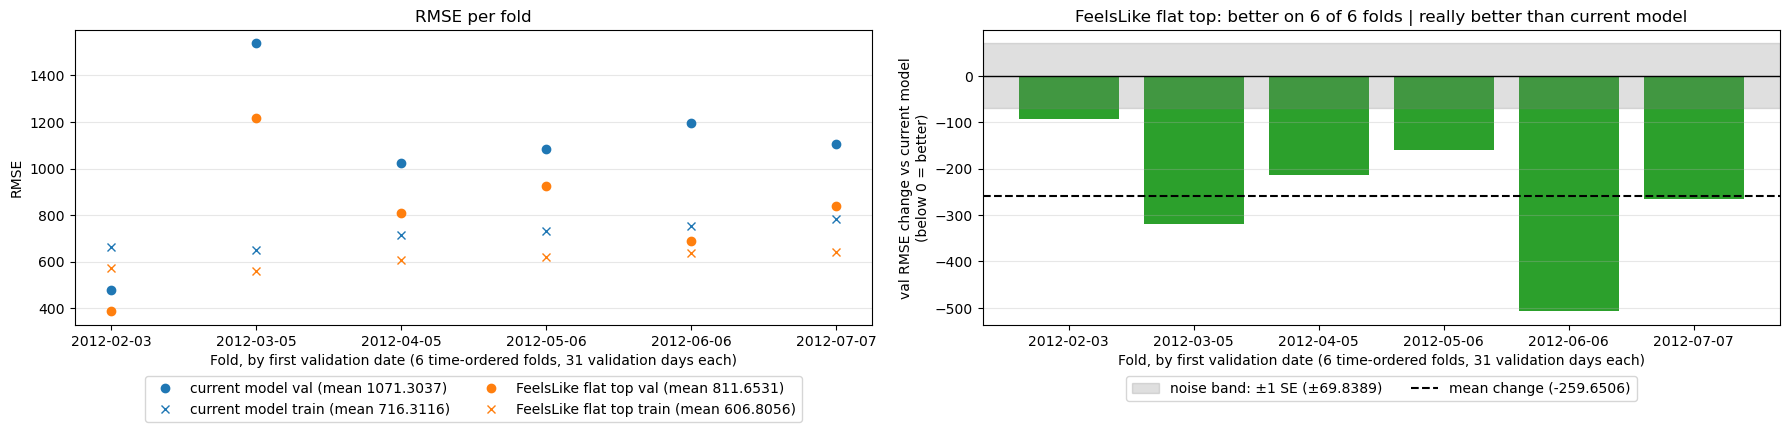

In [12]:
# Typed by hand from the table above: the lowest validation RMSE among the candidates that are really better.
STEP1_ACCEPTED = "FeelsLike flat top"

Q2_PLOTTING.cv_fold_scores(
	baseline=step1_scores,
	compare=step1_candidate_scores[STEP1_ACCEPTED],
	baseline_name="current model",
	compare_name=STEP1_ACCEPTED,
	folds=FOLDS,
	dates=train_df["Date"],
)

**Step 1.** Six of the 13 candidates are really better than the 11 raw attributes (1071.3037). The FeelsLike flat top is the best: validation RMSE 811.6531, a change of -259.6506 (SE 69.8389), better on all 6 folds, and it is accepted. The Temp flat top is close behind (820.4878, -250.8159), then Season one-hot (918.9697, -152.3339), Month one-hot (973.1747, -98.1290), Month sine / cosine (996.5259, -74.7777) and drop Temp (1061.9705, -9.3331, SE 4.4929). Two candidates are really worse: drop Weekday (+8.5997, SE 5.6986) and drop Year, which raises validation RMSE to 1866.4554 (+795.1518, SE 149.6293) and is better on 0 of 6 folds, so `Year` has to stay. The other five are within noise: drop Season, drop IsWorkday, drop IsHoliday, Weather one-hot and the Humidity hinge. Training RMSE falls with the accepted change (606.8056 against 716.3116), so the gain is a better fit.

## Step 2
The current model is Step 1's model with its accepted change applied. That change has left the pool, with every other candidate that touches the same attribute.

In [13]:
# Step 2 continues from Step 1 with its accepted change applied (STEP1_ACCEPTED, typed by hand above)
step2_columns = apply_change(step1_columns, CANDIDATES[STEP1_ACCEPTED])
step2_scores = step1_candidate_scores[STEP1_ACCEPTED]
step2_pool = remaining_pool(step1_pool, STEP1_ACCEPTED)
print(f"current model: {len(step2_columns)} columns | pool: {len(step2_pool)} candidates")

step2_table, step2_candidate_scores = score_candidates(
	columns=step2_columns,
	current_scores=step2_scores,
	pool=step2_pool
)
step2_table

current model: 11 columns | pool: 12 candidates


,val RMSE,train RMSE,change vs current,SE,folds better
Season one-hot,776.8127,586.3125,-34.8403,20.1339,5
Month sine / cosine,779.5315,576.3798,-32.1215,10.9953,5
drop IsWorkday,809.8384,606.9450,-1.8146,0.8081,5
current model,811.6531,606.8056,0.0000,0.0000,0
drop IsHoliday,811.7790,608.7009,0.1259,3.9396,2
drop Season,813.3145,636.7339,1.6614,15.5896,3
Weather one-hot,820.0964,589.0465,8.4433,23.9498,3
drop Weekday,821.4895,612.2870,9.8364,7.1325,1
Month one-hot,827.1694,562.0977,15.5163,36.9103,3
Humidity hinge,835.6186,601.2437,23.9656,20.1430,1


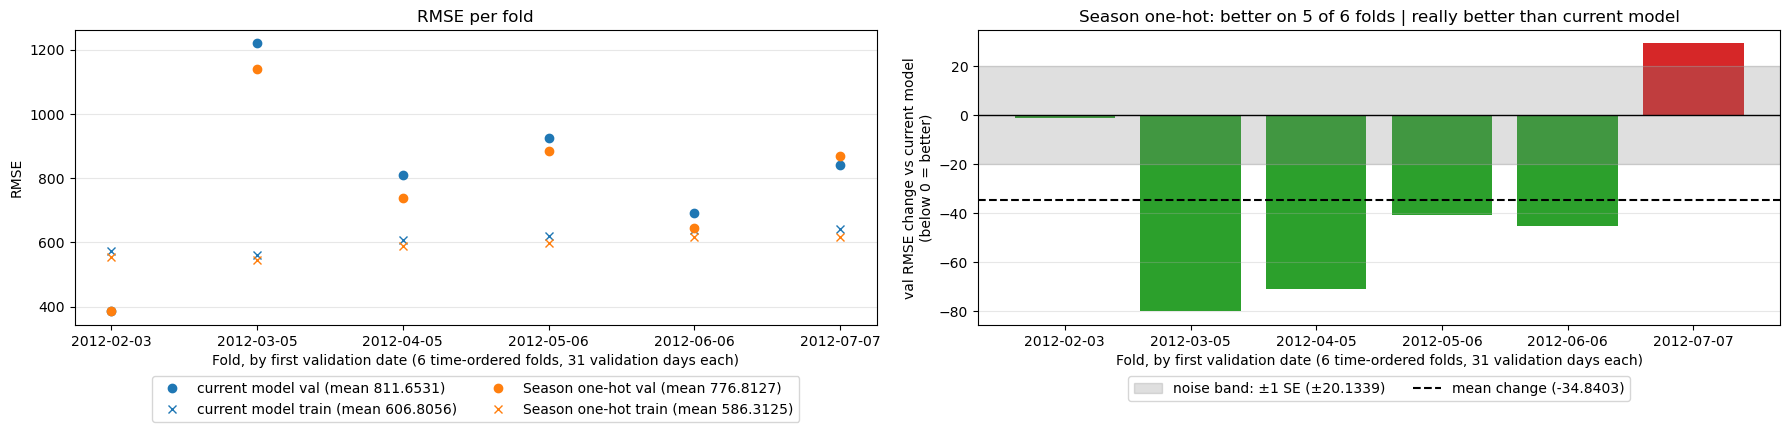

In [14]:
# Typed by hand from the table above: the lowest validation RMSE among the candidates that are really better.
STEP2_ACCEPTED = "Season one-hot"

Q2_PLOTTING.cv_fold_scores(
	baseline=step2_scores,
	compare=step2_candidate_scores[STEP2_ACCEPTED],
	baseline_name="current model",
	compare_name=STEP2_ACCEPTED,
	folds=FOLDS,
	dates=train_df["Date"],
)

**Step 2.** With the FeelsLike flat top in the model (811.6531), three of the 12 candidates are really better. Season one-hot has the lowest validation RMSE (776.8127, -34.8403, SE 20.1339, better on 5 of 6 folds) and is accepted. Month sine / cosine is almost level with it (779.5315, -32.1215) and has the smaller SE (10.9953), so this step is a close call. Drop IsWorkday is the third (809.8384, -1.8146, SE 0.8081). Two candidates changed sides from Step 1. Drop Temp was really better against the raw attributes and is now really worse (861.7234, +50.0703, SE 26.4117), and so is the Temp flat top (858.3836, +46.7305, SE 26.8697): with `FeelsLike` flat above 0.57, raw `Temp` is the only column left with a slope across the whole temperature range. Month one-hot went from really better to within noise (+15.5163, SE 36.9103). The Humidity hinge (+23.9656, SE 20.1430), drop Weekday (+9.8364, SE 7.1325) and drop Year (+906.4860) are really worse.

## Step 3
The current model is Step 2's model with its accepted change applied. That change has left the pool, with every other candidate that touches the same attribute.

In [15]:
# Step 3 continues from Step 2 with its accepted change applied (STEP2_ACCEPTED, typed by hand above)
step3_columns = apply_change(step2_columns, CANDIDATES[STEP2_ACCEPTED])
step3_scores = step2_candidate_scores[STEP2_ACCEPTED]
step3_pool = remaining_pool(step2_pool, STEP2_ACCEPTED)
print(f"current model: {len(step3_columns)} columns | pool: {len(step3_pool)} candidates")

step3_table, step3_candidate_scores = score_candidates(
	columns=step3_columns,
	current_scores=step3_scores,
	pool=step3_pool
)
step3_table

current model: 13 columns | pool: 10 candidates


,val RMSE,train RMSE,change vs current,SE,folds better
drop IsWorkday,775.4222,586.5188,-1.3905,0.9944,5
drop IsHoliday,776.3809,588.2162,-0.4319,4.2516,3
current model,776.8127,586.3125,0.0000,0.0000,0
Month sine / cosine,780.0156,574.9527,3.2029,16.9467,3
Weather one-hot,785.4696,569.1115,8.6568,23.7765,3
drop Weekday,788.1471,591.7287,11.3344,6.8968,1
Humidity hinge,795.6283,580.0911,18.8156,21.3345,2
drop Temp,803.7691,595.0857,26.9564,12.1880,0
Temp flat top,804.2031,593.6862,27.3904,15.4385,0
Month one-hot,826.4413,560.8894,49.6285,43.3463,2


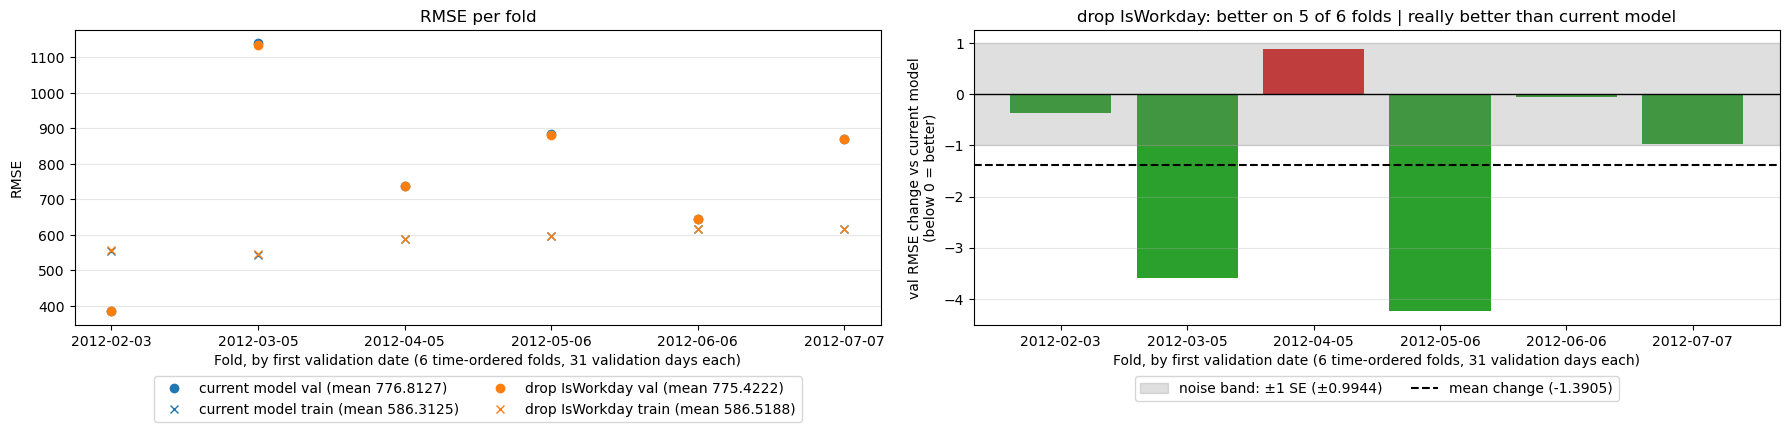

In [16]:
# Typed by hand from the table above: the lowest validation RMSE among the candidates that are really better.
STEP3_ACCEPTED = "drop IsWorkday"

Q2_PLOTTING.cv_fold_scores(
	baseline=step3_scores,
	compare=step3_candidate_scores[STEP3_ACCEPTED],
	baseline_name="current model",
	compare_name=STEP3_ACCEPTED,
	folds=FOLDS,
	dates=train_df["Date"],
)

**Step 3.** With Season one-hot in the model (776.8127), only one of the 10 candidates is really better: drop IsWorkday, at 775.4222 (-1.3905, SE 0.9944, better on 5 of 6 folds). It is accepted, on a thin margin. Month sine / cosine, the runner-up of Step 2, is now within noise (780.0156, +3.2029, SE 16.9467), so Season one-hot already carries what it offered. Drop IsHoliday (-0.4319, SE 4.2516), Weather one-hot (+8.6568, SE 23.7765) and the Humidity hinge (+18.8156, SE 21.3345) are within noise too. Drop Weekday (+11.3344, SE 6.8968), drop Temp (+26.9564, SE 12.1880), the Temp flat top (+27.3904, SE 15.4385), Month one-hot (+49.6285, SE 43.3463) and drop Year (+948.3078) are really worse.

## Step 4
The current model is Step 3's model with its accepted change applied. That change has left the pool, with every other candidate that touches the same attribute. This is the last step. Its table is the evidence for stopping, so no candidate is typed in below it and there is no chart.

In [17]:
# Step 4 continues from Step 3 with its accepted change applied (STEP3_ACCEPTED, typed by hand above)
step4_columns = apply_change(step3_columns, CANDIDATES[STEP3_ACCEPTED])
step4_scores = step3_candidate_scores[STEP3_ACCEPTED]
step4_pool = remaining_pool(step3_pool, STEP3_ACCEPTED)
print(f"current model: {len(step4_columns)} columns | pool: {len(step4_pool)} candidates")

step4_table, step4_candidate_scores = score_candidates(
	columns=step4_columns,
	current_scores=step4_scores,
	pool=step4_pool
)
step4_table

current model: 12 columns | pool: 9 candidates


,val RMSE,train RMSE,change vs current,SE,folds better
drop IsHoliday,775.0997,588.8015,-0.3225,4.2381,2
current model,775.4222,586.5188,0.0000,0.0000,0
Month sine / cosine,778.8157,575.4260,3.3935,16.0652,3
Weather one-hot,783.8681,569.3464,8.4459,23.6645,3
drop Weekday,786.8553,591.9360,11.4331,6.8644,1
Humidity hinge,794.6214,580.2493,19.1992,21.5116,1
drop Temp,802.7457,595.3108,27.3235,12.0939,0
Temp flat top,803.3018,593.8924,27.8796,15.3015,0
Month one-hot,824.8128,561.3603,49.3906,42.6023,1
drop Year,1723.8648,830.2721,948.4426,90.7045,0


**Step 4.** With `IsWorkday` dropped (775.4222, 12 columns), none of the 9 candidates is really better, so the selection stops. Only drop IsHoliday has a lower validation RMSE (775.0997), and its change of -0.3225 is far inside its SE (4.2381) and better on only 2 of 6 folds. The rule accepts a change only when it is really better, so `IsHoliday` stays. Month sine / cosine (+3.3935, SE 16.0652), Weather one-hot (+8.4459, SE 23.6645) and the Humidity hinge (+19.1992, SE 21.5116) are within noise. Drop Weekday (+11.4331, SE 6.8644), drop Temp (+27.3235, SE 12.0939), the Temp flat top (+27.8796, SE 15.3015), Month one-hot (+49.3906, SE 42.6023) and drop Year (+948.4426) are really worse.

## Selected Columns
The columns of the last step's current model: the 11 raw attributes with every accepted change applied. The list is typed by hand from the steps above. It is scored with closed form `LinearRegression` and charted against the 11 raw attributes.

12


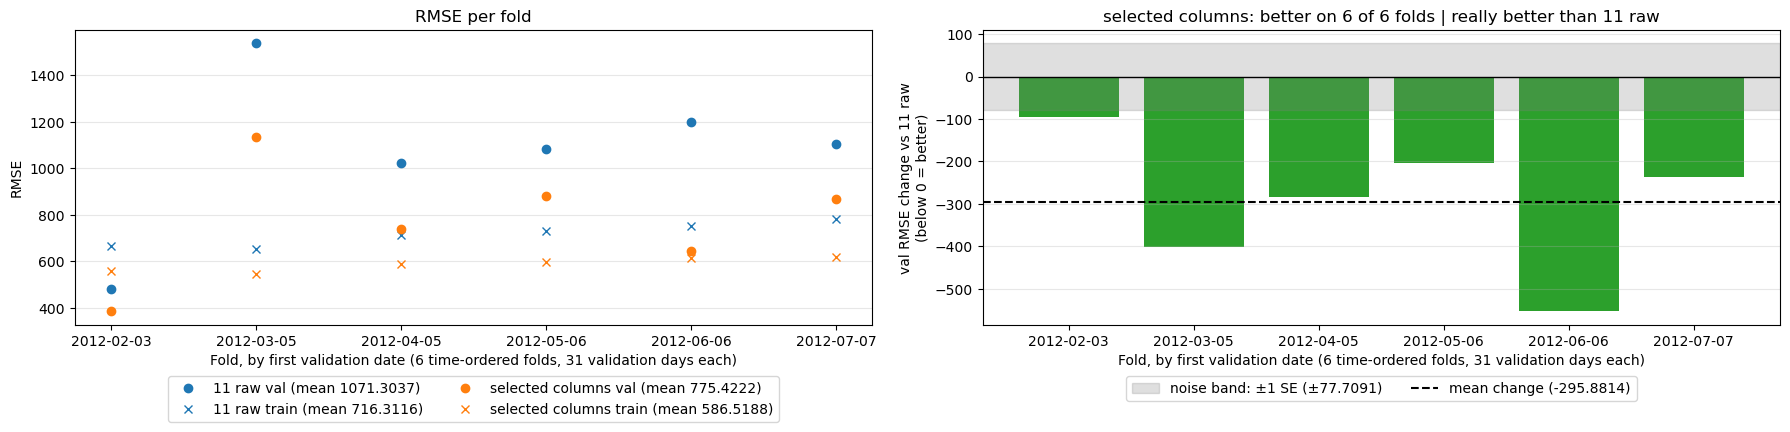

In [18]:
# Typed by hand from the accepted changes of the steps above: raw FeelsLike is replaced by its flat top,
# the Season code is replaced by its one-hot columns, and IsWorkday is dropped.
# "Remove One" below checks each of these changes.
BEST_FEATURES = [
	"Temp", "Humidity", "Wind", "Year", "IsHoliday", "Month", "Weekday", "Weather",
	"FeelsLike flat top 0.57",
	"Season 2", "Season 3", "Season 4",
]
print(len(BEST_FEATURES))

best_closedform_val_scores, best_closedform_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=BEST_FEATURES,
	estimator=LinearRegression(),
	folds=FOLDS,
	target=TARGET
)

Q2_PLOTTING.cv_fold_scores(
	baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
	compare=(best_closedform_val_scores, best_closedform_train_scores),
	baseline_name="11 raw",
	compare_name="selected columns",
	folds=FOLDS,
	dates=train_df["Date"],
)

## Remove One
Each run undoes one accepted change of the selected columns and is charted against the selected columns.

| Experiment | Change to the selected columns |
|---|---|
| FeelsLike back to raw | the flat top is replaced by raw `FeelsLike` |
| Season back to the code | the one-hot columns are replaced by the raw `Season` code |
| with IsWorkday added back | raw `IsWorkday` is added |

A change that still earns its place makes the model really worse when it is undone.

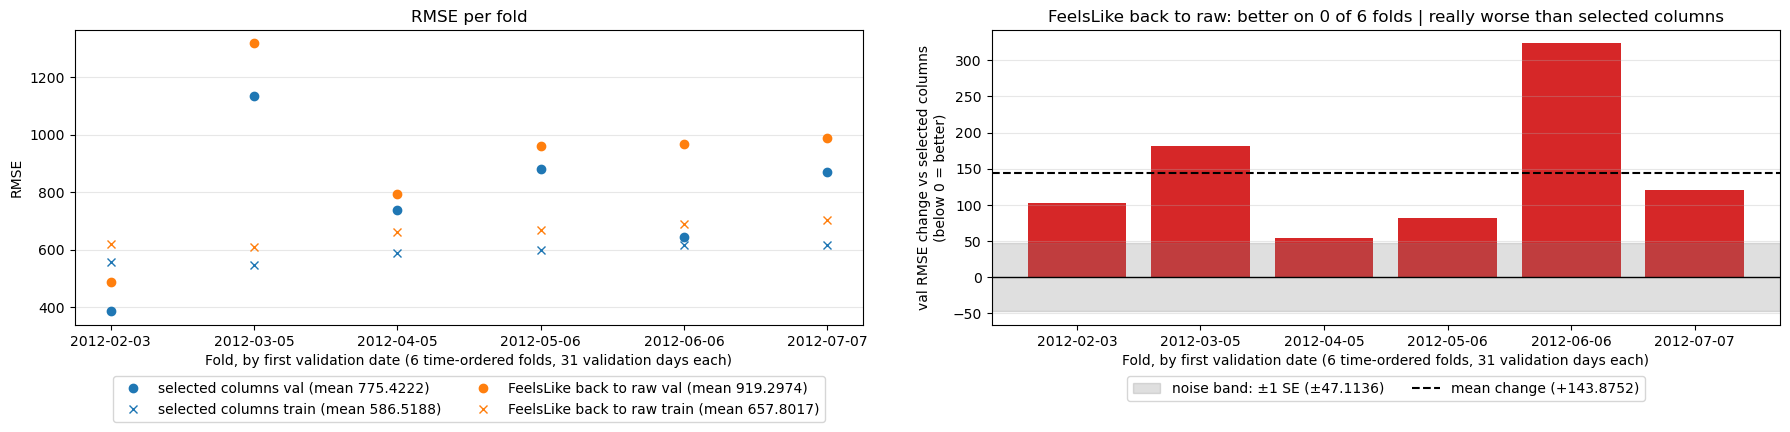

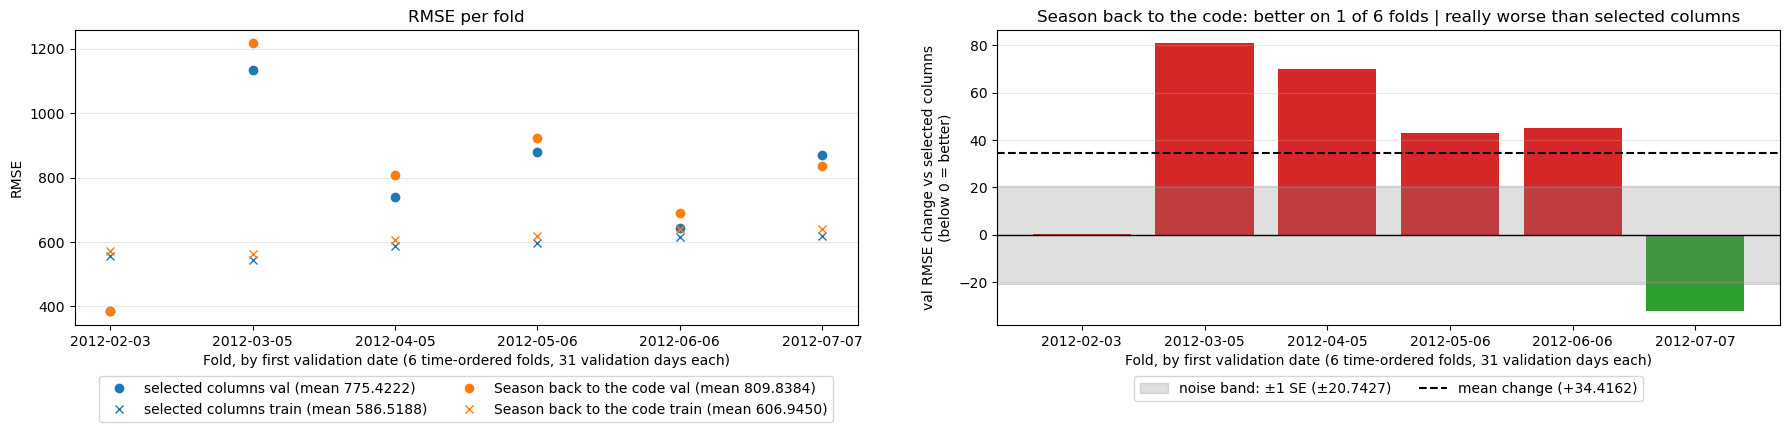

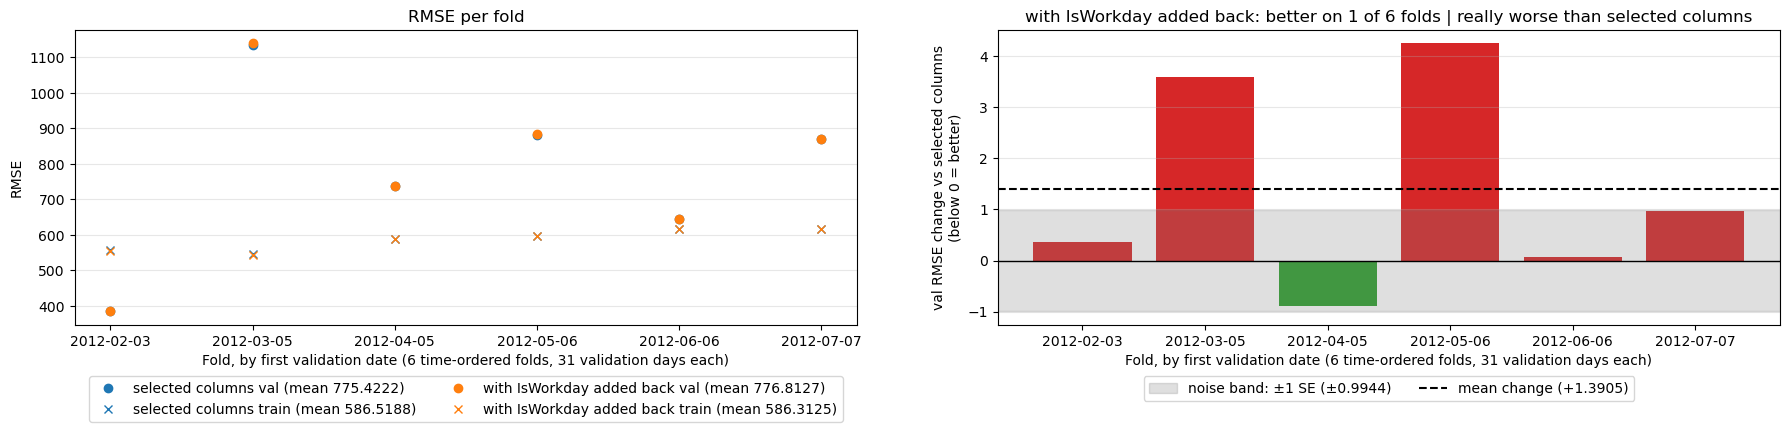

In [19]:
REMOVE_ONE = {
	"FeelsLike back to raw": [col for col in BEST_FEATURES if col != "FeelsLike flat top 0.57"] + ["FeelsLike"],
	"Season back to the code": [col for col in BEST_FEATURES if col not in SEASON_ONE_HOT] + ["Season"],
	"with IsWorkday added back": BEST_FEATURES + ["IsWorkday"],
}

remove_one_scores = {}
for name, columns in REMOVE_ONE.items():
	remove_one_scores[name] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=columns,
		estimator=LinearRegression(),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(best_closedform_val_scores, best_closedform_train_scores),
		compare=remove_one_scores[name],
		baseline_name="selected columns",
		compare_name=name,
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Selection Summary

In [20]:
selection_runs = {
	"selected columns": (best_closedform_val_scores, best_closedform_train_scores),
	"11 raw": (closedform_lr_val_scores, closedform_lr_train_scores),
}
for name, val_train in remove_one_scores.items():
	selection_runs[name] = val_train

selection_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs selected": (val - best_closedform_val_scores).mean(),
		"SE": standard_error(diff=val - best_closedform_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < best_closedform_val_scores),
	}
	for name, (val, train) in selection_runs.items()
}).T.sort_values("change vs selected")
selection_summary["folds better"] = selection_summary["folds better"].astype(int)
selection_summary.round(4)

,val RMSE,train RMSE,change vs selected,SE,folds better
selected columns,775.4222,586.5188,0.0000,0.0000,0
with IsWorkday added back,776.8127,586.3125,1.3905,0.9944,1
Season back to the code,809.8384,606.9450,34.4162,20.7427,1
FeelsLike back to raw,919.2974,657.8017,143.8752,47.1136,0
11 raw,1071.3037,716.3116,295.8814,77.7091,0


**Which changes carry the gain.** Together the three accepted changes lower validation RMSE from 1071.3037 to 775.4222, a change of 295.8814 (SE 77.7091), and the 11 raw attributes are better on 0 of 6 folds. Each change still earns its place: undoing it is worse by more than 1 SE. Taking the FeelsLike flat top back to the raw column costs the most (919.2974, +143.8752, SE 47.1136, better on 0 of 6 folds), then Season back to its code (809.8384, +34.4162, SE 20.7427), then adding `IsWorkday` back (776.8127, +1.3905, SE 0.9944). The last one is a thin margin, so it is the weakest of the three choices. Two results differ from what Q2C suggested. Both of its redundant pairs stay in the model: raw `Temp` next to the FeelsLike flat top, and the `Month` code next to Season one-hot, because dropping `Temp` is really worse from Step 2 on. And Month sine / cosine, Q2C's first choice for a calendar shape, is within noise once Season one-hot is in. Training RMSE (586.5188) stays well below validation RMSE (775.4222), the same gap every model here shows. These 12 columns (`BEST_FEATURES`) are the feature set carried forward.

# Stochastic Gradient Descent (SGD)
Every model from here on is fit on `BEST_FEATURES`, the 12 columns chosen in Step-by-Step Selection. The columns are standardized inside each training fold (`StandardScaler`), and the target is left in its own units. Plain SGD is first compared with closed form on the same 12 columns. Every penalty and learning rate experiment is then compared with plain SGD.

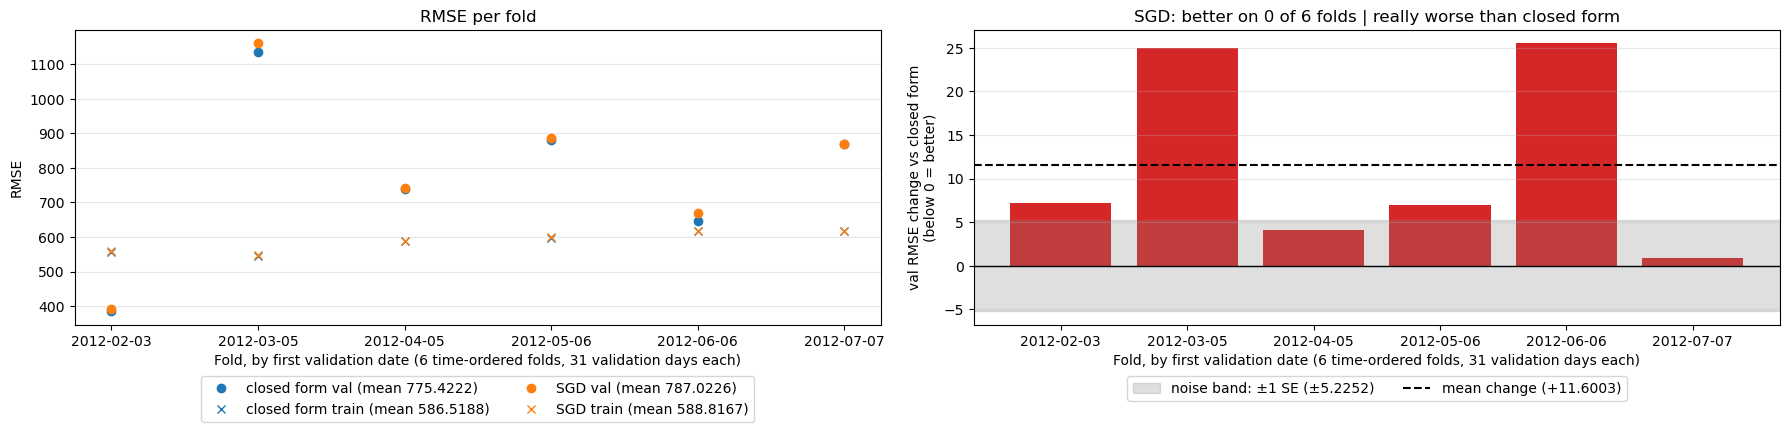

In [21]:
sgd_val_scores, sgd_train_scores = Q2_CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=BEST_FEATURES,
	estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty=None, random_state=42)),
	folds=FOLDS,
	target=TARGET
)

Q2_PLOTTING.cv_fold_scores(
	baseline=(best_closedform_val_scores, best_closedform_train_scores),
	compare=(sgd_val_scores, sgd_train_scores),
	baseline_name="closed form",
	compare_name="SGD",
	folds=FOLDS,
	dates=train_df["Date"],
)

**SGD against closed form.** On the same 12 columns, plain SGD (no penalty) scores a validation RMSE of 787.0226 against 775.4222 for closed form. The chart's verdict is really worse: the mean change (+11.6003) is outside the ±1 SE band (±5.2252), and SGD is better on 0 of 6 folds. The gap is largest on the folds that start on 2012-03-05 and 2012-06-06, at about 25 each. Its training RMSE (588.8167) is close to closed form's (586.5188). So SGD gets near the closed form solution by iterating but stops a little short of it, and that small shortfall on the training rows costs more on the validation days. Plain SGD is the baseline for every penalty and learning rate experiment below.

## Lasso

In [22]:
lasso_scores = {}

### Lasso > Penalty

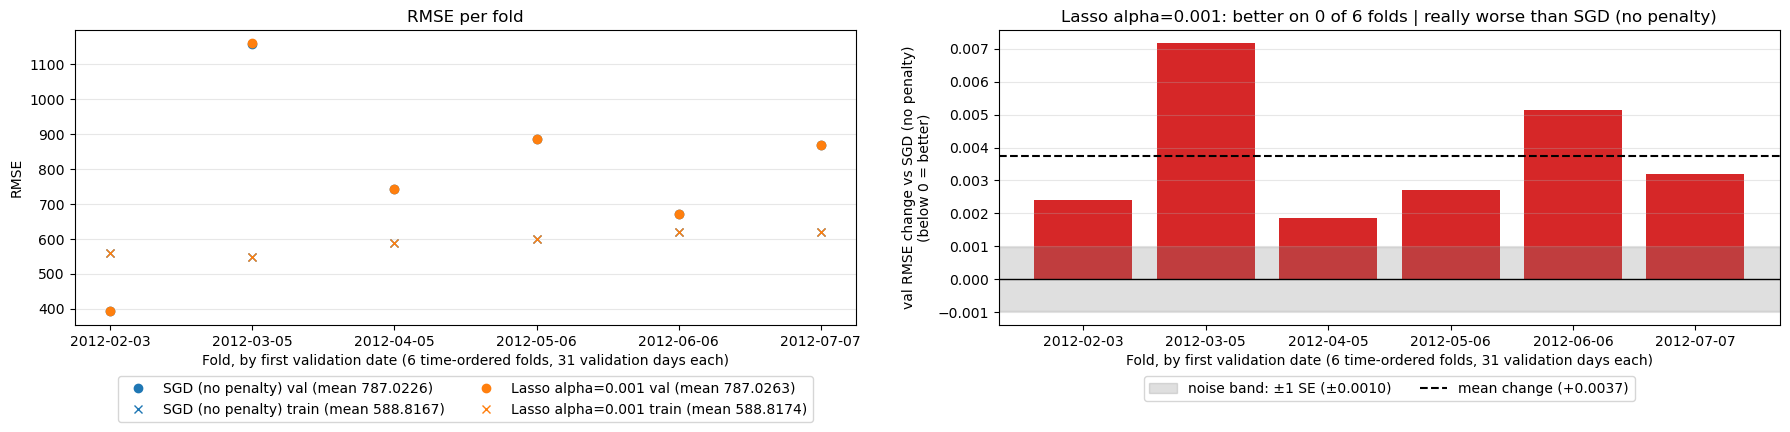

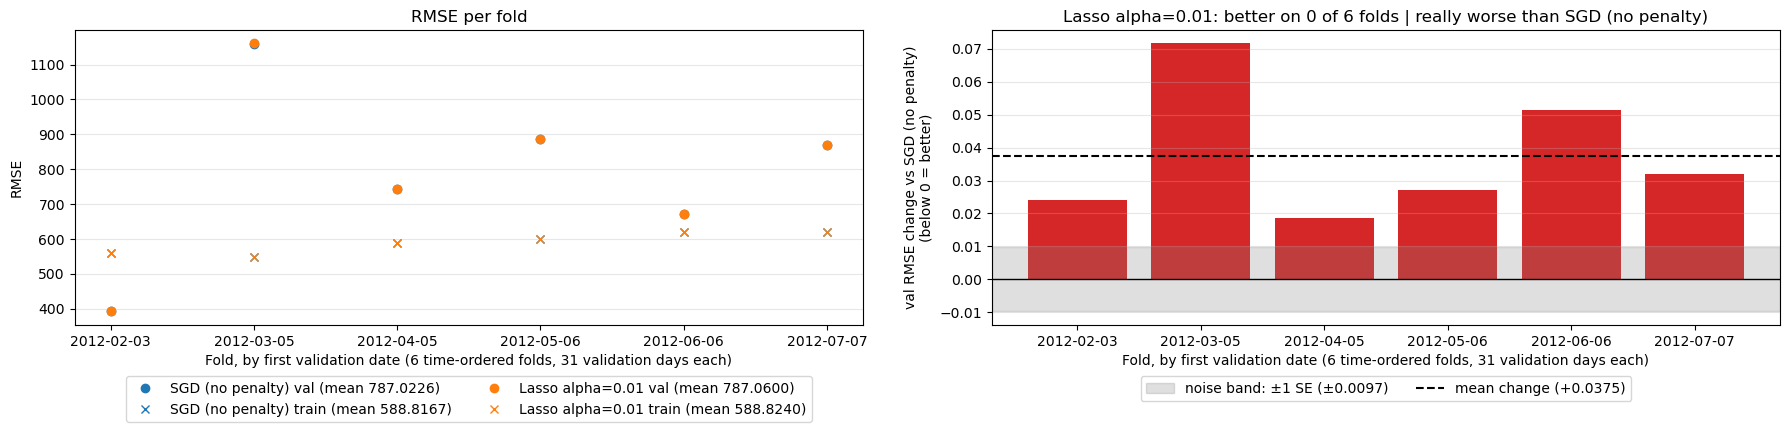

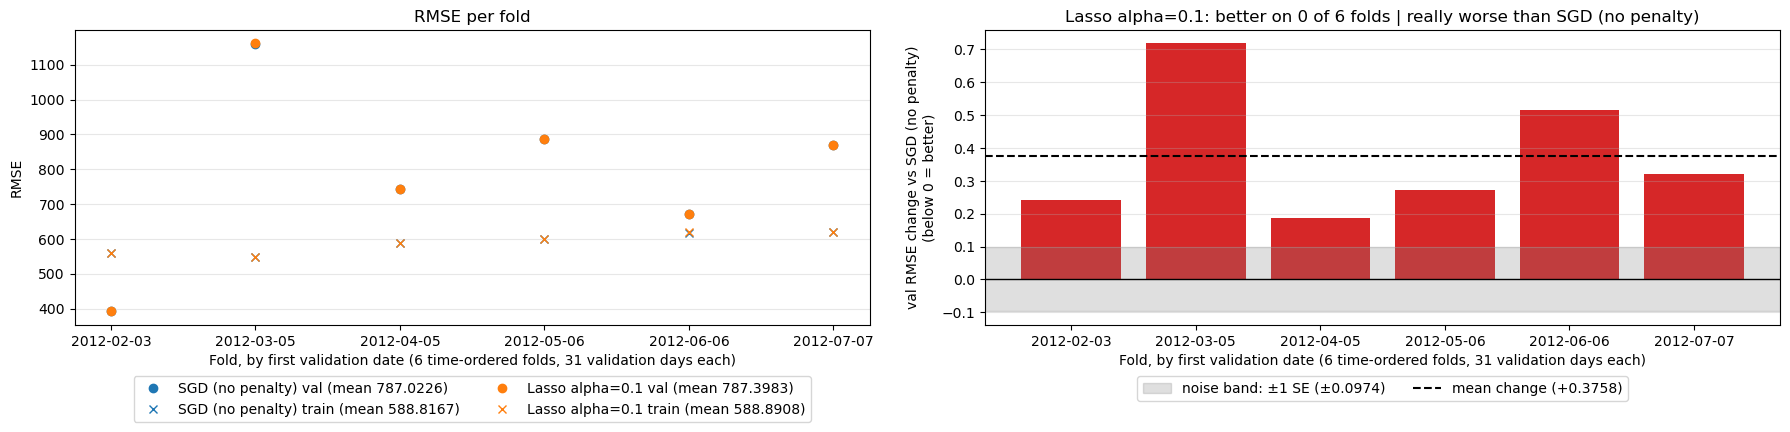

In [23]:
for alpha in ALPHAS:
	lasso_scores[("alpha", alpha)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l1', alpha=alpha, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso alpha={alpha}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

### Lasso > Learning Rate

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

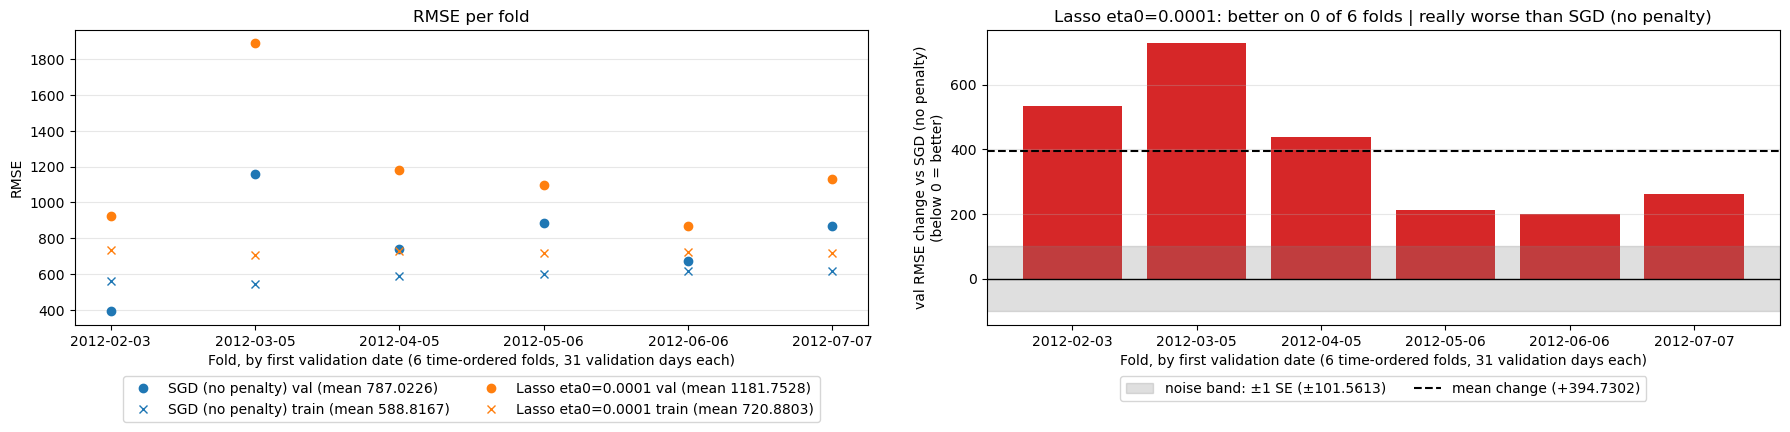

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

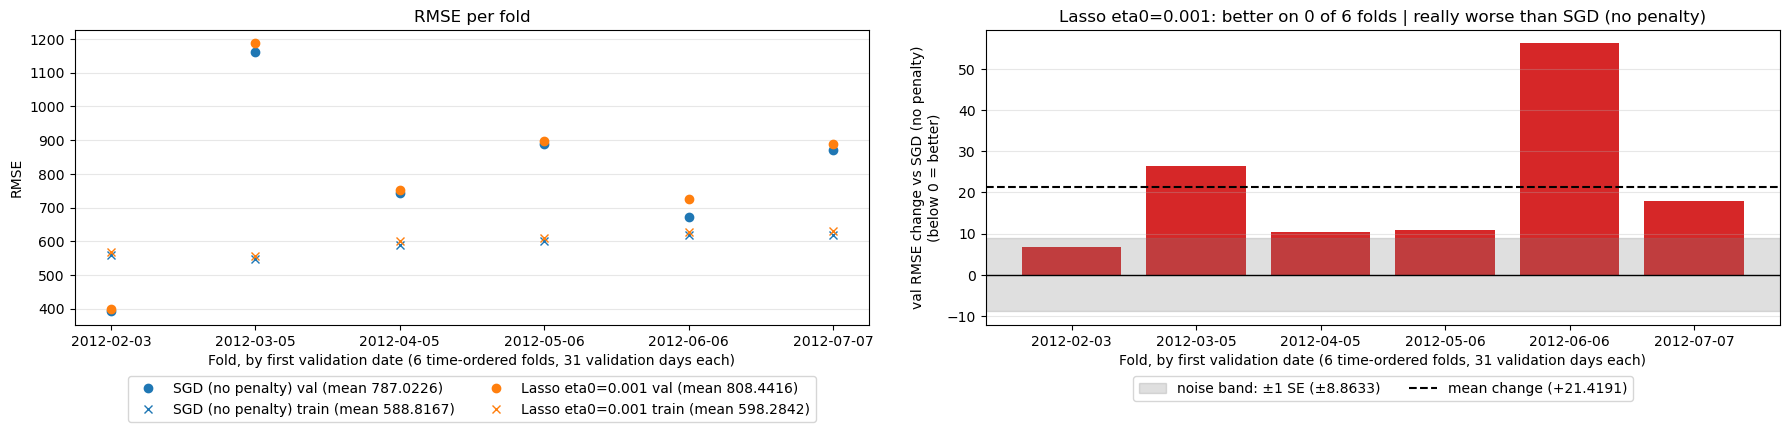

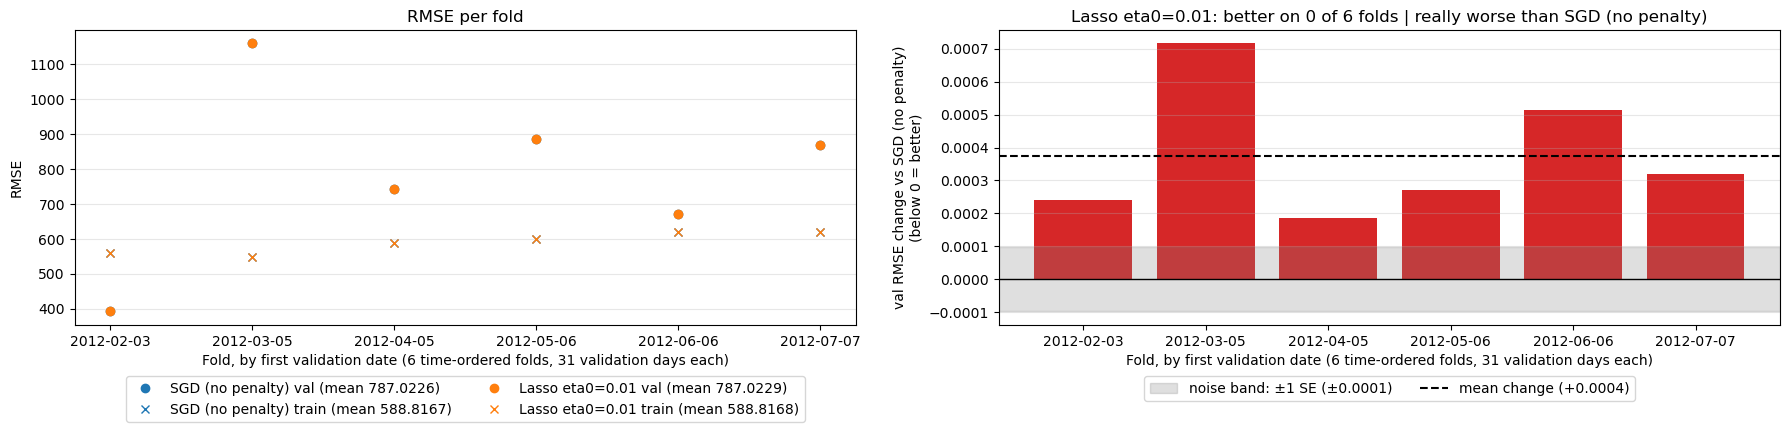

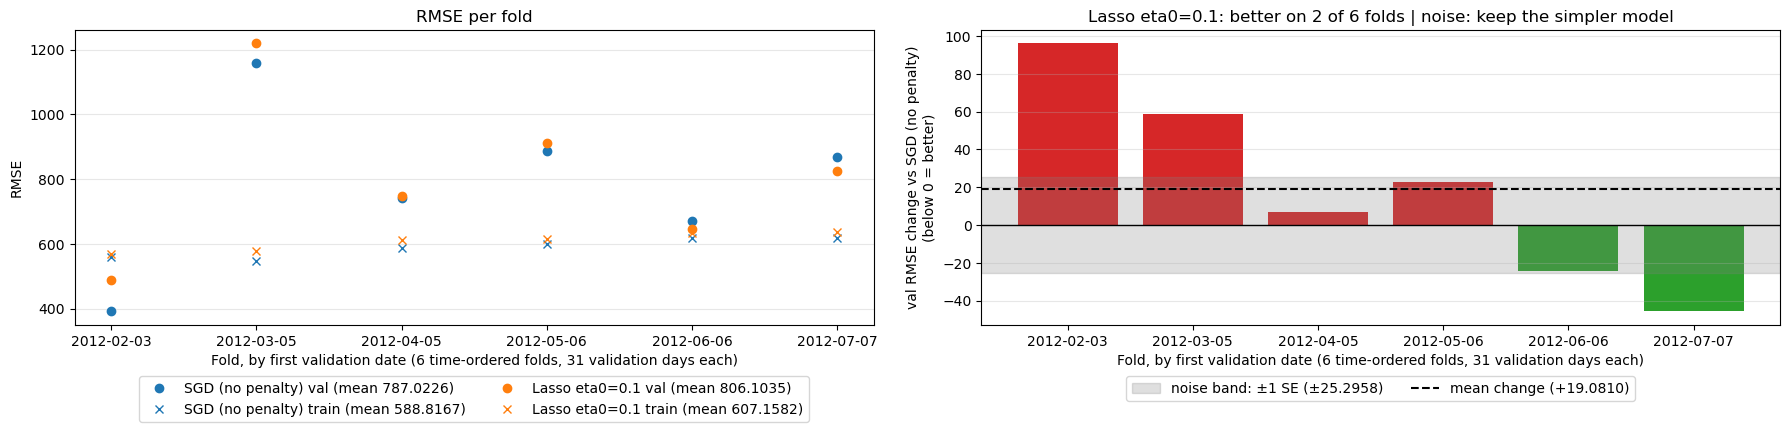

In [24]:
for eta0 in LEARNING_RATES:
	lasso_scores[("eta0", eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l1', eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso eta0={eta0}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Ridge

In [25]:
ridge_scores = {}

### Ridge > Penalty

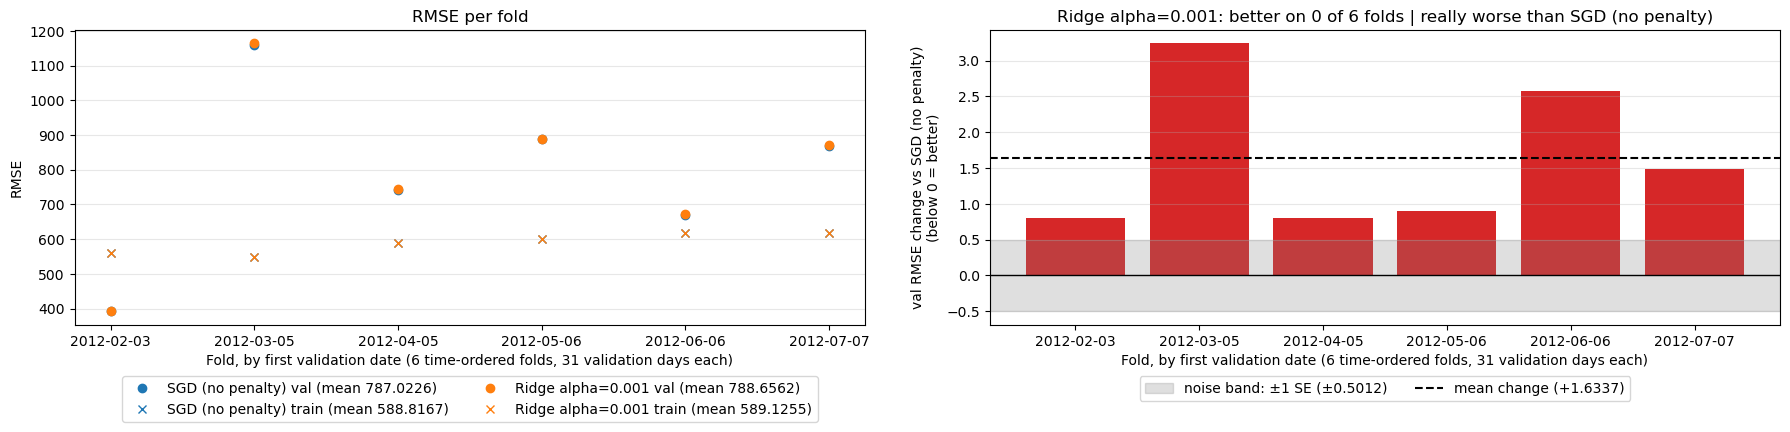

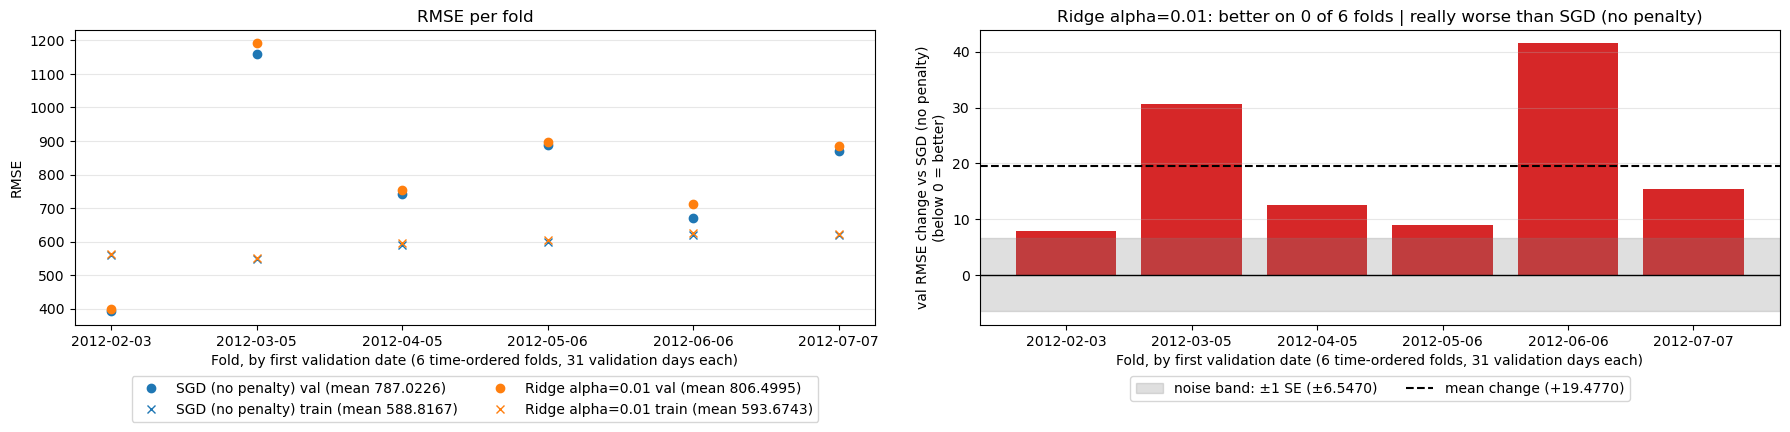

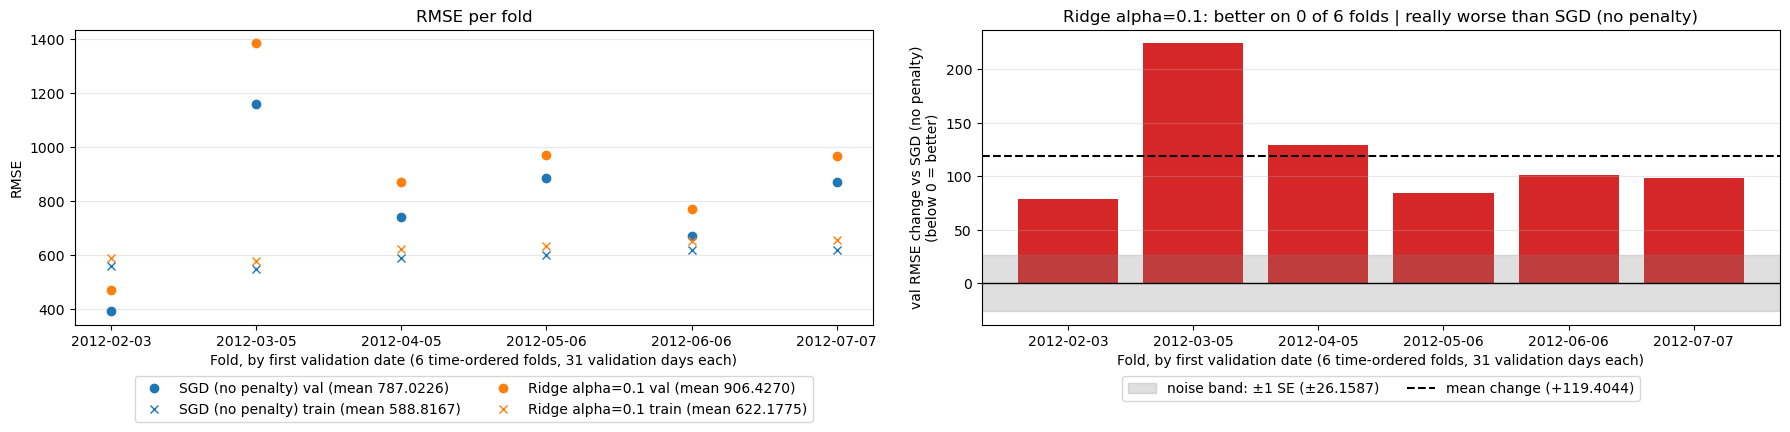

In [26]:
for alpha in ALPHAS:
	ridge_scores[("alpha", alpha)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l2', alpha=alpha, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge alpha={alpha}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

### Ridge > Learning Rate

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

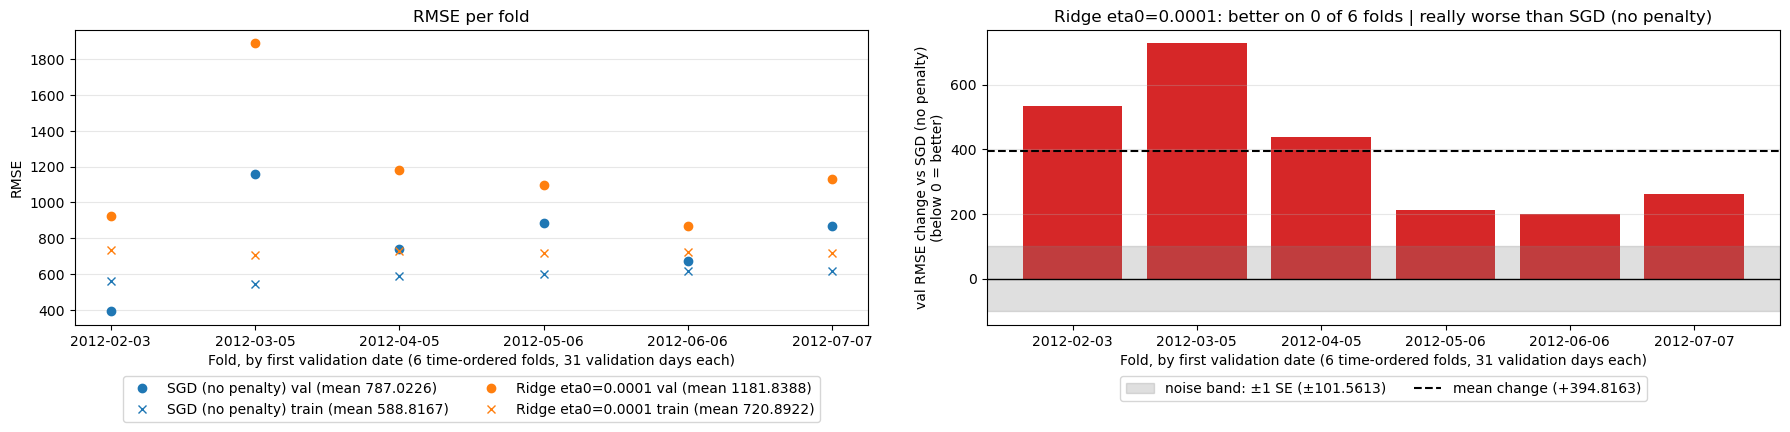

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

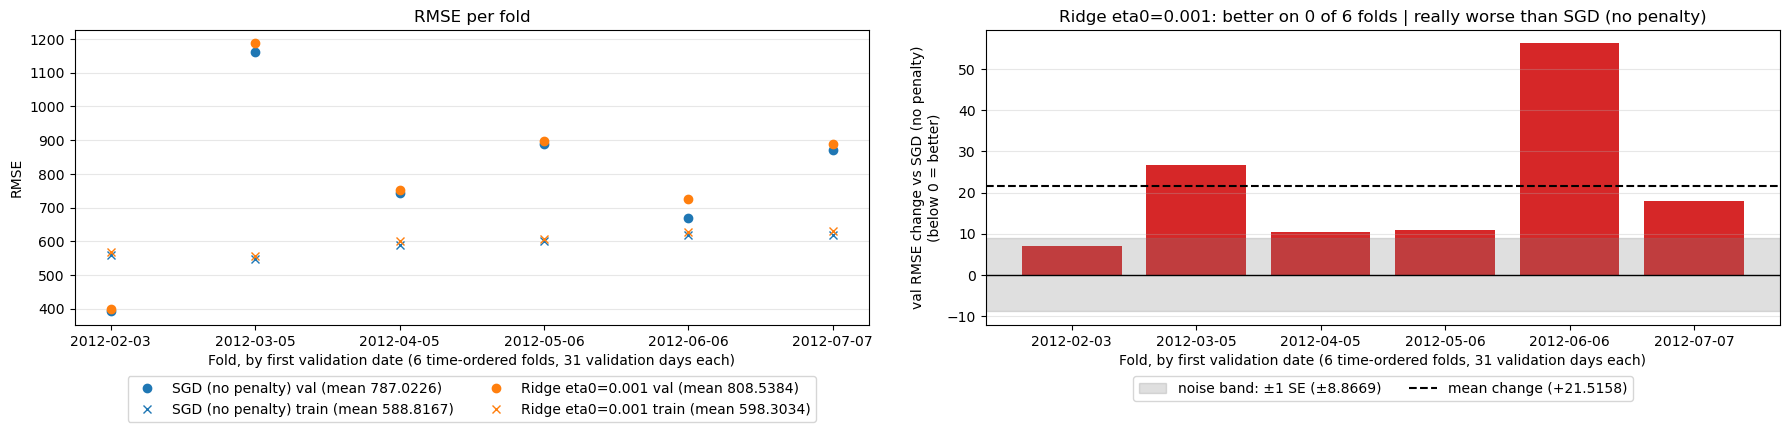

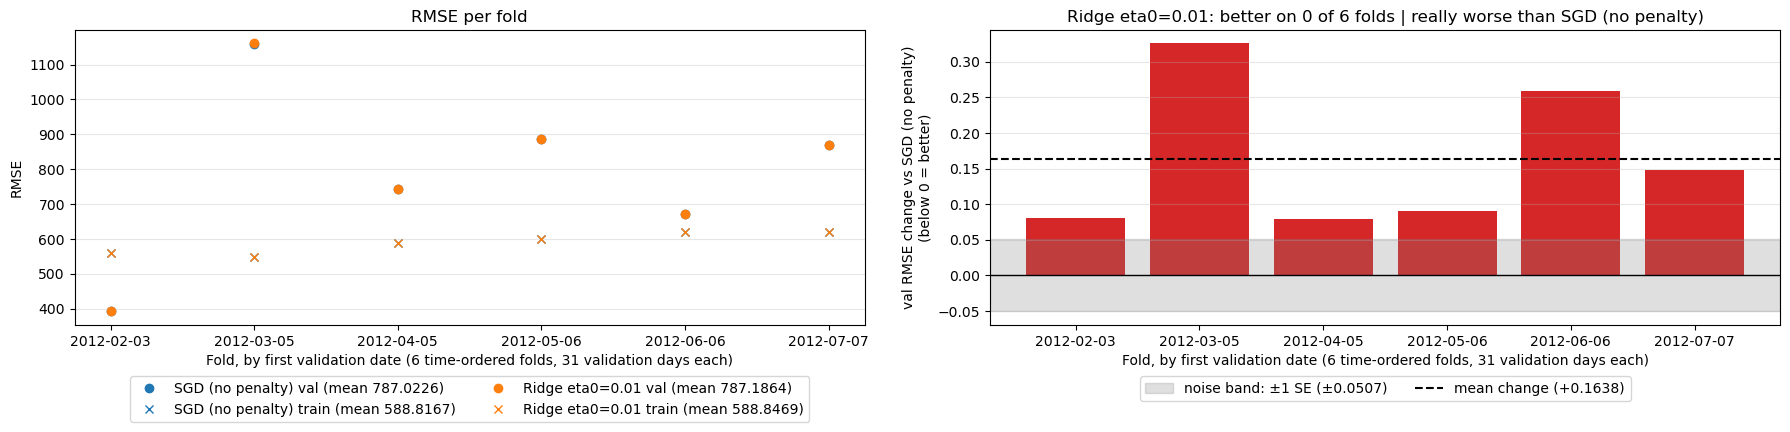

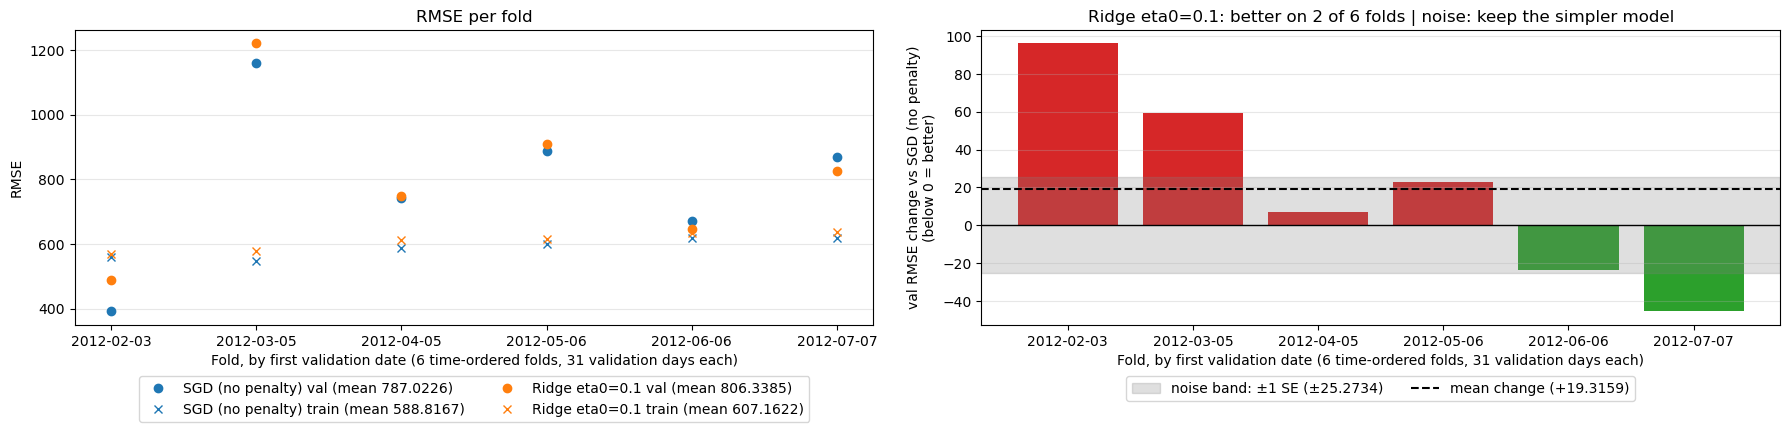

In [27]:
for eta0 in LEARNING_RATES:
	ridge_scores[("eta0", eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l2', eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge eta0={eta0}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Elastic Net

In [28]:
elasticnet_scores = {}

### Elastic Net > Penalty

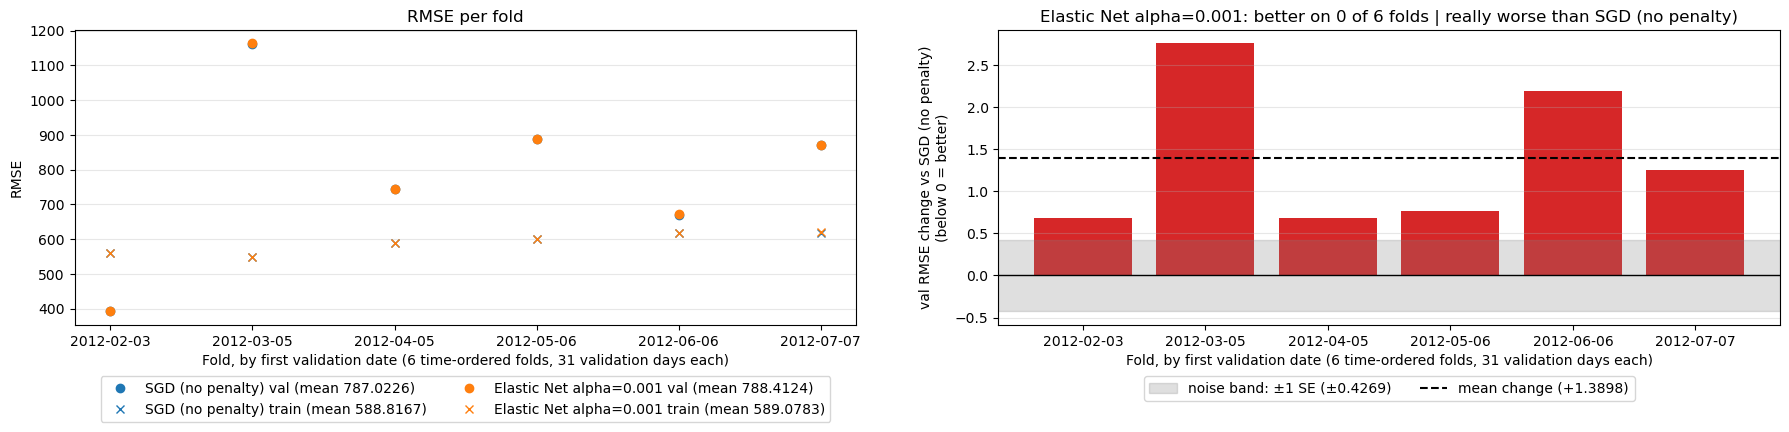

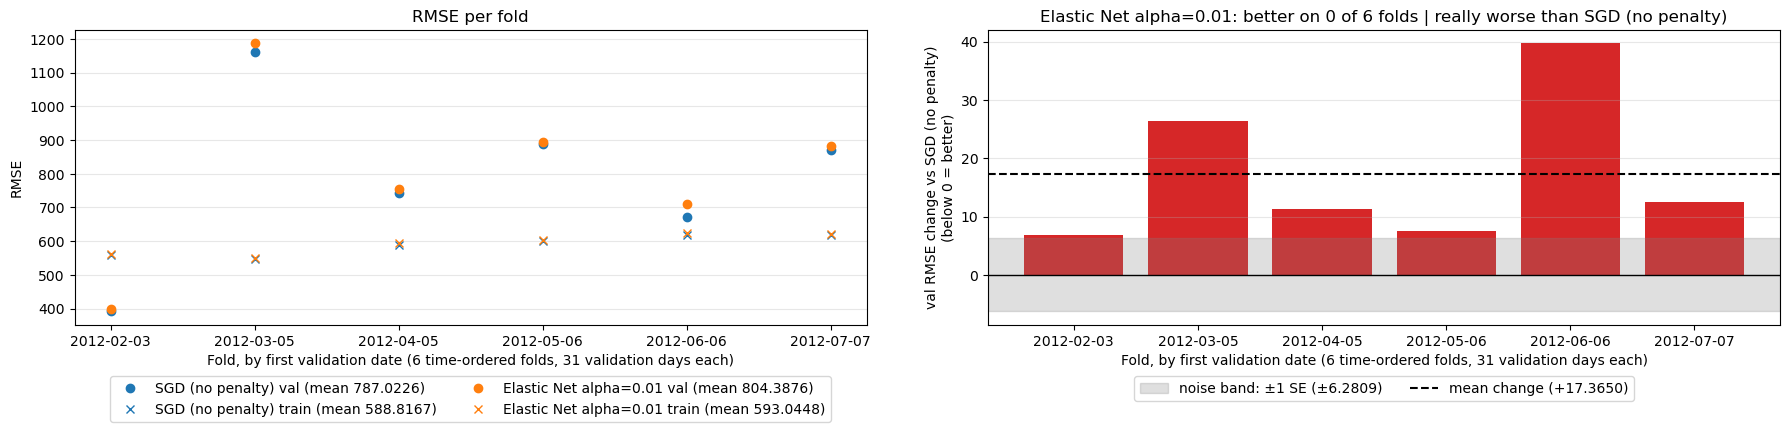

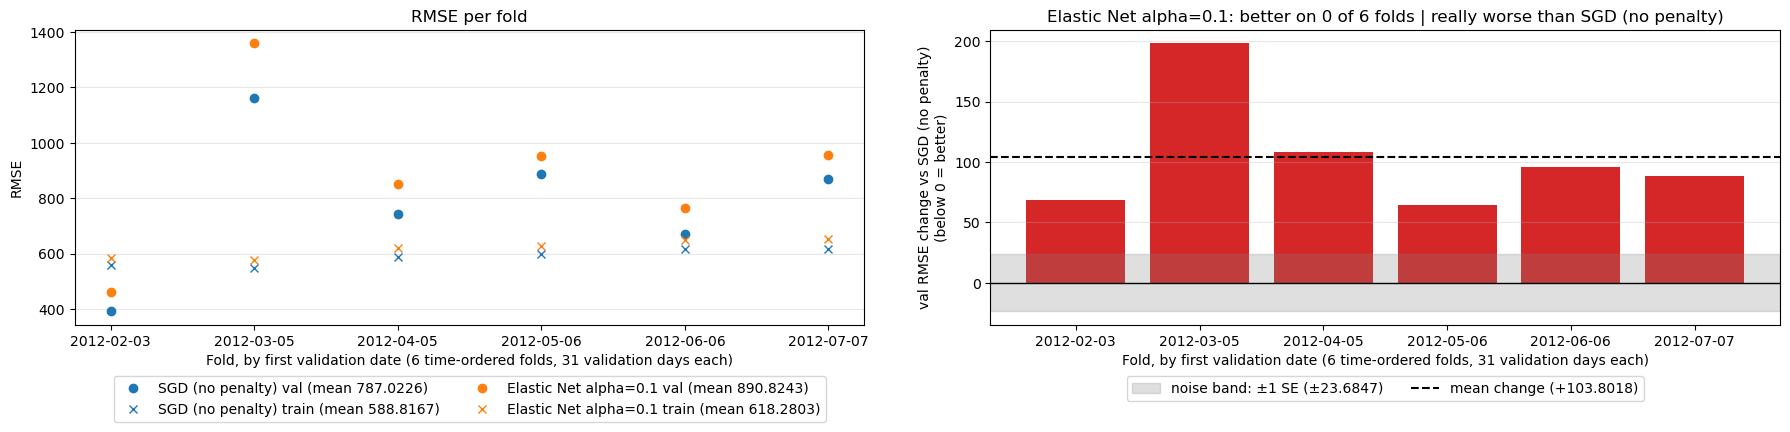

In [29]:
for alpha in ALPHAS:
	elasticnet_scores[("alpha", alpha)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', alpha=alpha, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net alpha={alpha}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

### Elastic Net > Learning Rate

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

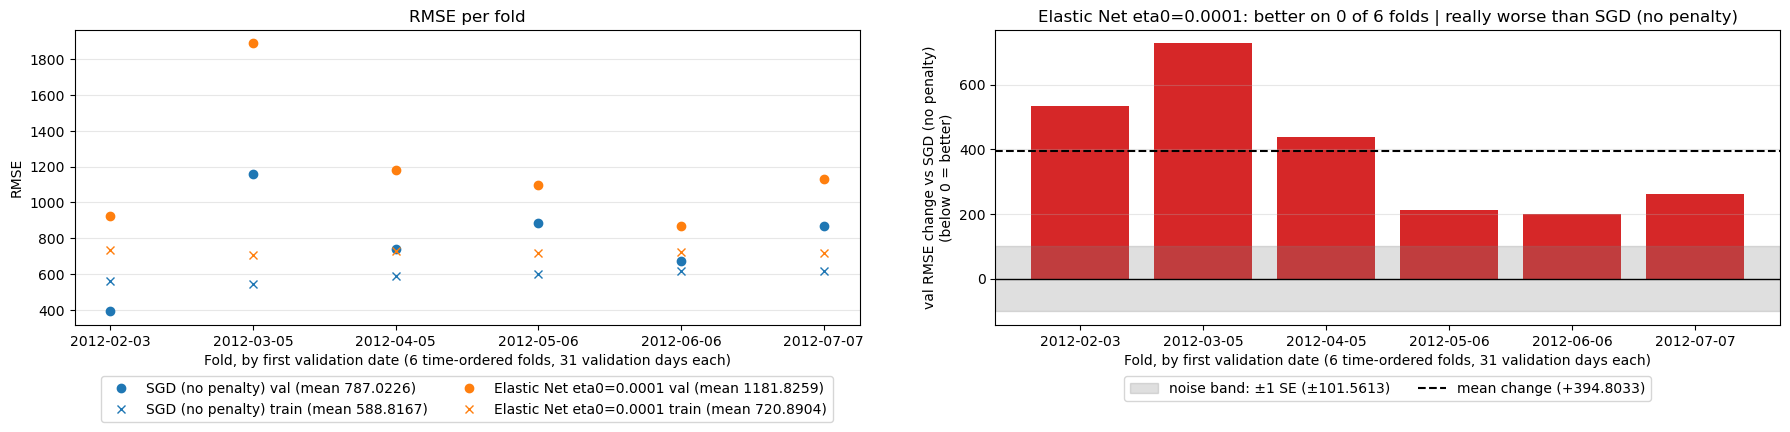

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

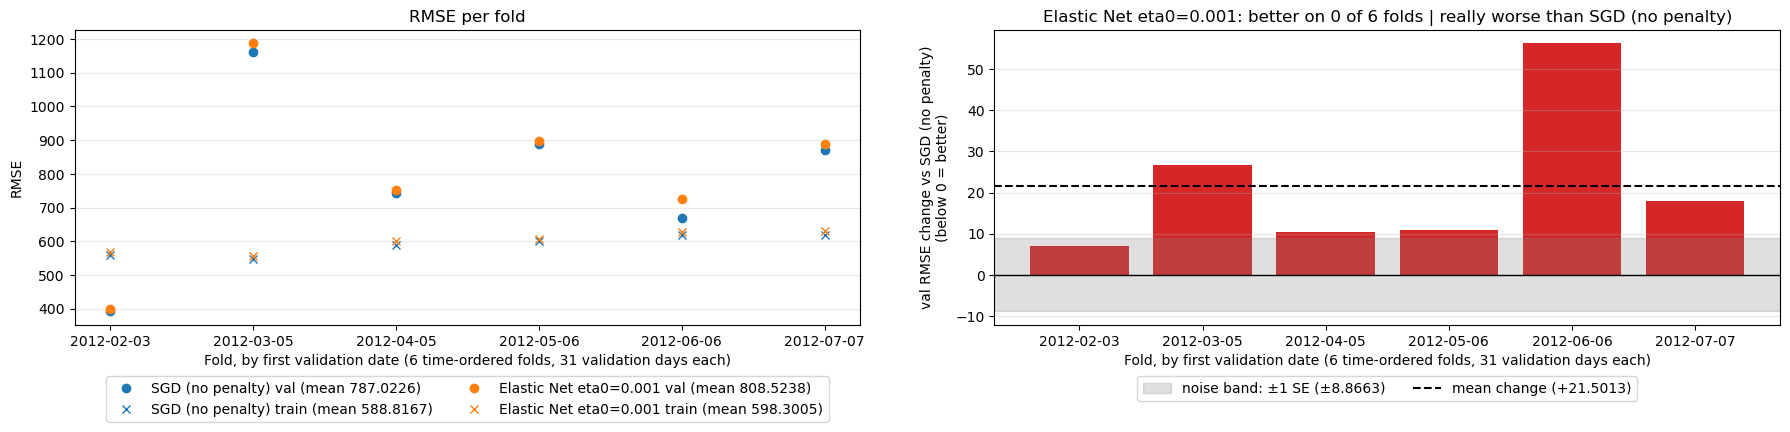

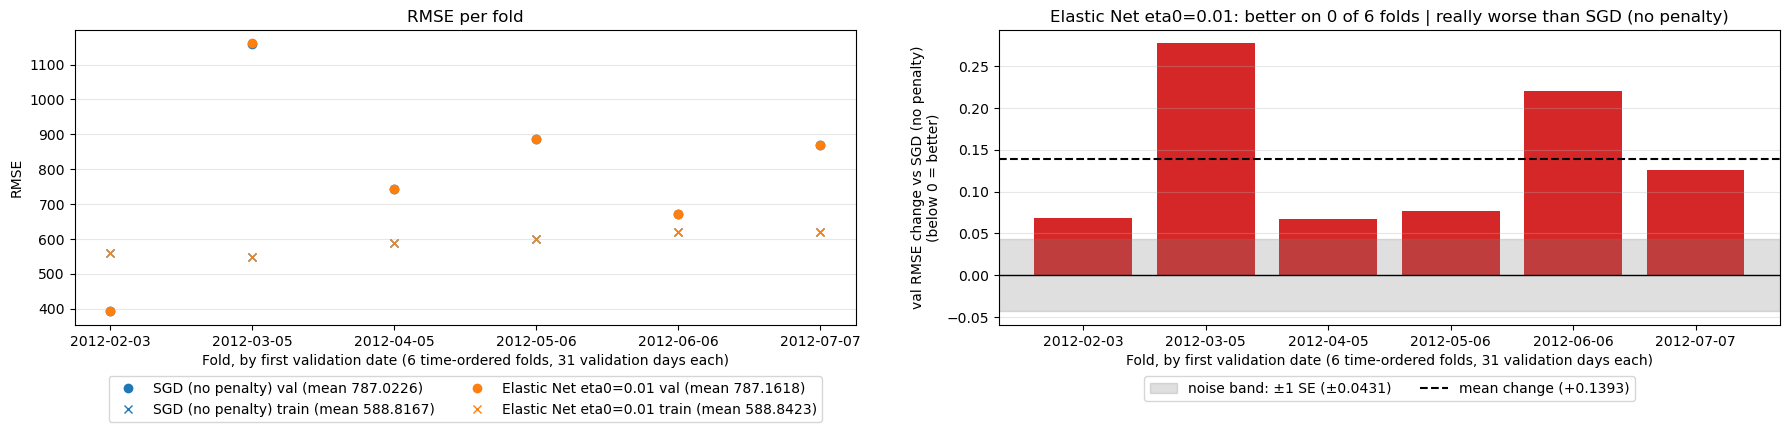

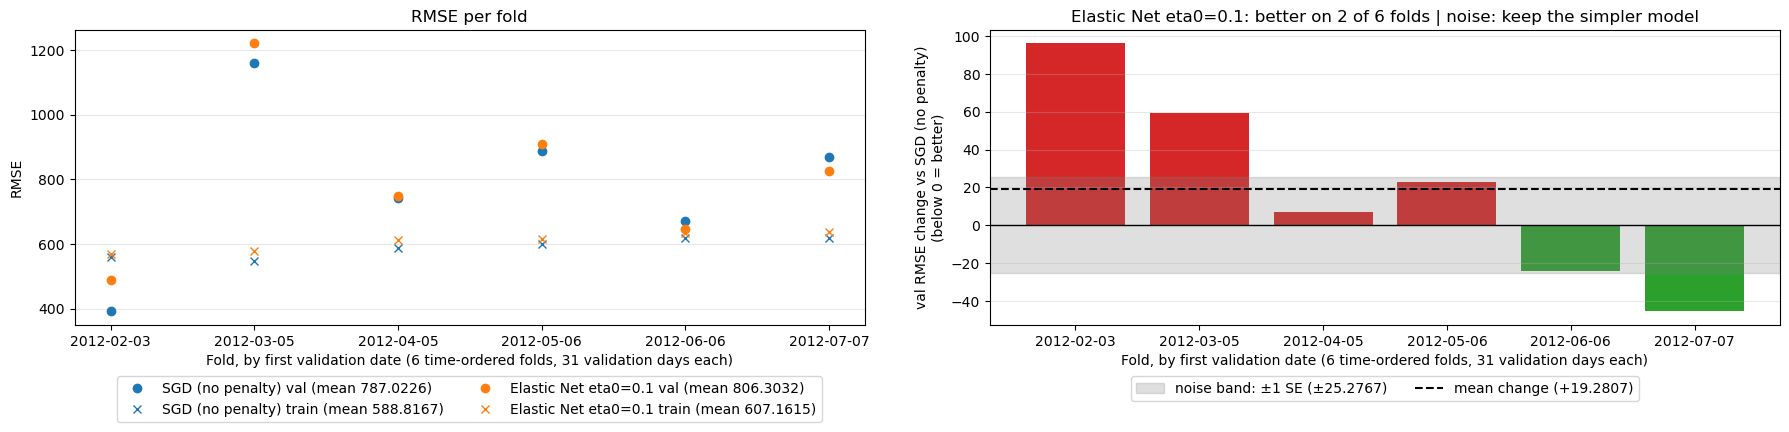

In [30]:
for eta0 in LEARNING_RATES:
	elasticnet_scores[("eta0", eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

	Q2_PLOTTING.cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net eta0={eta0}",
		folds=FOLDS,
		dates=train_df["Date"],
	)

## Penalty Summary

In [31]:
runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "alpha":
			runs[f"{name} alpha={value}"] = val_train

summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in runs.items()
}).T.sort_values("change vs SGD")
summary["folds better"] = summary["folds better"].astype(int)
summary.round(4)

,val RMSE,train RMSE,change vs SGD,SE,folds better
SGD (no penalty),787.0226,588.8167,0.0000,0.0000,0
Lasso alpha=0.001,787.0263,588.8174,0.0037,0.0010,0
Lasso alpha=0.01,787.0600,588.8240,0.0375,0.0097,0
Lasso alpha=0.1,787.3983,588.8908,0.3758,0.0974,0
Elastic Net alpha=0.001,788.4124,589.0783,1.3898,0.4269,0
Ridge alpha=0.001,788.6562,589.1255,1.6337,0.5012,0
Elastic Net alpha=0.01,804.3876,593.0448,17.3650,6.2809,0
Ridge alpha=0.01,806.4995,593.6743,19.4770,6.5470,0
Elastic Net alpha=0.1,890.8243,618.2803,103.8018,23.6847,0
Ridge alpha=0.1,906.4270,622.1775,119.4044,26.1587,0


**Impact of the penalty.** No penalty helps. Every penalized run scores above plain SGD (787.0226), is better on 0 of 6 folds, and has a change larger than its SE, so all nine are really worse. Lasso costs the least: 787.0263 at alpha 0.001 (+0.0037, SE 0.0010), 787.0600 at alpha 0.01 and 787.3983 at alpha 0.1 (+0.3758, SE 0.0974). Ridge costs the most: 788.6562 at alpha 0.001 (+1.6337), 806.4995 at alpha 0.01 (+19.4770, SE 6.5470) and 906.4270 at alpha 0.1 (+119.4044, SE 26.1587). Elastic Net sits between them (788.4124, 804.3876 and 890.8243). So at the same alpha the L2 penalty costs the most and the L1 penalty the least. Training RMSE rises with validation RMSE (622.1775 for Ridge at alpha 0.1, against 588.8167 for plain SGD), so a strong penalty underfits. Plain SGD does have a wide gap between training and validation RMSE (588.8167 against 787.0226), but no penalty narrows it, so shrinking the coefficients is not what the later days need.

## Learning Rate Summary

In [32]:
learning_rate_runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "eta0":
			learning_rate_runs[f"{name} eta0={value}"] = val_train

learning_rate_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in learning_rate_runs.items()
}).T.sort_values("change vs SGD")
learning_rate_summary["folds better"] = learning_rate_summary["folds better"].astype(int)
learning_rate_summary.round(4)

,val RMSE,train RMSE,change vs SGD,SE,folds better
SGD (no penalty),787.0226,588.8167,0.0000,0.0000,0
Lasso eta0=0.01,787.0229,588.8168,0.0004,0.0001,0
Elastic Net eta0=0.01,787.1618,588.8423,0.1393,0.0431,0
Ridge eta0=0.01,787.1864,588.8469,0.1638,0.0507,0
Lasso eta0=0.1,806.1035,607.1582,19.0810,25.2958,2
Elastic Net eta0=0.1,806.3032,607.1615,19.2807,25.2767,2
Ridge eta0=0.1,806.3385,607.1622,19.3159,25.2734,2
Lasso eta0=0.001,808.4416,598.2842,21.4191,8.8633,0
Elastic Net eta0=0.001,808.5238,598.3005,21.5013,8.8663,0
Ridge eta0=0.001,808.5384,598.3034,21.5158,8.8669,0


**Impact of the learning rate.** Each run changes only eta0 and leaves alpha at its default. eta0 0.01 is the value plain SGD already uses, so at 0.01 all three penalties are next to it (787.0229 to 787.1864). No other value is better. At 0.001 all three rise to about 808.5 (+21.4191 to +21.5158, SE about 8.87) and are better on 0 of 6 folds, so they are really worse. At 0.1 they score about 806.2 (+19.0810 to +19.3159), but the SE is about 25.3 and they are better on 2 of 6 folds, so the verdict is noise: a higher mean and an unstable result from fold to fold. At 0.0001 all three reach about 1181.8 (+394.7302 to +394.8163, SE 101.5613) and are better on 0 of 6 folds. Training RMSE rises with validation RMSE at the small learning rates (720.8803 at 0.0001 and 598.2842 at 0.001, against 588.8167 for plain SGD), so those models are underfit, not overfit. The `ConvergenceWarning`s printed under these cells say the same thing: some runs reach the iteration limit before they converge. The three penalties score almost the same at every eta0, so here the learning rate matters far more than the penalty.

## Hyperparameter Grid
Every combination of penalty, alpha and learning rate (eta0), each compared against plain SGD.

In [33]:
grid_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	grid_scores[(penalty, alpha, eta0)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in grid_scores.items()
}).T
grid.index.names = ["penalty", "alpha", "eta0"]
grid["folds better"] = grid["folds better"].astype(int)
grid.sort_values("val RMSE").round(4)

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

val RMSE  train RMSE  change vs SGD        SE  \
penalty    alpha eta0                                                     
l1         0.001 0.0100   787.0263    588.8174         0.0037    0.0010   
           0.010 0.0100   787.0600    588.8240         0.0375    0.0097   
           0.100 0.0100   787.3983    588.8908         0.3758    0.0974   
elasticnet 0.001 0.0100   788.4124    589.0783         1.3898    0.4269   
l2         0.001 0.0100   788.6562    589.1255         1.6337    0.5012   
l1         0.100 0.1000   803.3147    603.5994        16.2921   26.2872   
elasticnet 0.010 0.0100   804.3876    593.0448        17.3650    6.2809   
l1         0.001 0.1000   806.1081    607.1532        19.0856   25.2973   
           0.010 0.1000   806.1554    607.1044        19.1329   25.3115   
l2         0.010 0.0100   806.4995    593.6743        19.4770    6.5470   
elasticnet 0.001 0.1000   808.0982    607.2104        21.0756   25.1141   
l1         0.001 0.0010   808.4434    598.2844        21.4208    8.8629   
l2         0.001 0.1000   808.4473    607.2256        21.4248   25.0835   
l1         0.010 0.0010   808.4609    598.2868        21.4383    8.8585   
           0.100 0.0010   808.6366    598.3106        21.6141    8.8153   
elasticnet 0.001 0.0010   809.2658    598.4484        22.2432    8.8954   
l2         0.001 0.0010   809.4110    598.4775        22.3884    8.9017   
elasticnet 0.010 0.0010   816.7011    599.9806        29.6786    9.4121   
l2         0.010 0.0010   818.1592    600.2907        31.1367    9.5569   
elasticnet 0.010 0.1000   826.4297    612.7027        39.4072   24.1146   
l2         0.010 0.1000   829.3915    613.3903        42.3689   24.1384   
elasticnet 0.100 0.0100   890.8243    618.2803       103.8018   23.6847   
                 0.1000   894.4406    631.1156       107.4180   22.7619   
                 0.0010   895.5927    621.1920       108.5701   23.8274   
l2         0.100 0.0100   906.4270    622.1775       119.4044   26.1587   
                 0.0010   910.9734    625.1087       123.9508   26.7807   
                 0.1000   915.3911    636.3544       128.3686   27.7451   
l1         0.001 0.0001  1181.7554    720.8807       394.7329  101.5616   
           0.010 0.0001  1181.7821    720.8848       394.7595  101.5644   
           0.100 0.0001  1182.0484    720.9254       395.0258  101.5931   
elasticnet 0.001 0.0001  1182.4868    720.9814       395.4642  101.5619   
l2         0.001 0.0001  1182.6158    720.9993       395.5933  101.5619   
elasticnet 0.010 0.0001  1189.0941    721.9114       402.0716  101.5589   
l2         0.010 0.0001  1190.3841    722.0970       403.3615  101.5560   
elasticnet 0.100 0.0001  1254.6362    732.9087       467.6137  100.8352   
l2         0.100 0.0001  1267.2411    735.3613       480.2185  100.5815   

                         folds better  
penalty    alpha eta0                  
l1         0.001 0.0100             0  
           0.010 0.0100             0  
           0.100 0.0100             0  
elasticnet 0.001 0.0100             0  
l2         0.001 0.0100             0  
l1         0.100 0.1000             3  
elasticnet 0.010 0.0100             0  
l1         0.001 0.1000             2  
           0.010 0.1000             2  
l2         0.010 0.0100             0  
elasticnet 0.001 0.1000             2  
l1         0.001 0.0010             0  
l2         0.001 0.1000             2  
l1         0.010 0.0010             0  
           0.100 0.0010             0  
elasticnet 0.001 0.0010             0  
l2         0.001 0.0010             0  
elasticnet 0.010 0.0010             0  
l2         0.010 0.0010             0  
elasticnet 0.010 0.1000             1  
l2         0.010 0.1000             1  
elasticnet 0.100 0.0100             0  
                 0.1000             0  
                 0.0010             0  
l2         0.100 0.0100             0  
                 0.0010             0  
                 0.1000             0  
l1         0.00

### Elastic Net l1_ratio
Elastic Net only: l1_ratio sets the mix of the two penalties (0 = all Ridge, 1 = all Lasso). Ridge and Lasso ignore it.

In [34]:
L1_RATIOS = [0.15, 0.5, 0.85]

elasticnet_grid_scores = {}
for alpha, eta0, l1_ratio in product(ALPHAS, LEARNING_RATES, L1_RATIOS):
	elasticnet_grid_scores[(alpha, eta0, l1_ratio)] = Q2_CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', alpha=alpha, eta0=eta0, l1_ratio=l1_ratio, random_state=42)),
		folds=FOLDS,
		target=TARGET
	)

elasticnet_grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores, test_train_ratio=TEST_TRAIN_RATIO),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in elasticnet_grid_scores.items()
}).T
elasticnet_grid.index.names = ["alpha", "eta0", "l1_ratio"]
elasticnet_grid["folds better"] = elasticnet_grid["folds better"].astype(int)
elasticnet_grid.sort_values("val RMSE").round(4)

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

val RMSE  train RMSE  change vs SGD        SE  \
alpha eta0   l1_ratio                                                   
0.001 0.0100 0.85       787.2714    588.8626         0.2489    0.0768   
             0.50       787.8425    588.9695         0.8199    0.2526   
             0.15       788.4124    589.0783         1.3898    0.4269   
0.010 0.0100 0.85       789.5014    589.2924         2.4789    0.7552   
             0.50       798.9176    591.1465        11.8950    5.9454   
             0.15       804.3876    593.0448        17.3650    6.2809   
0.001 0.1000 0.85       806.4605    607.1596        19.4379   25.2637   
             0.50       807.2809    607.1808        20.2583   25.1873   
             0.15       808.0982    607.2104        21.0756   25.1141   
      0.0010 0.85       808.5885    598.3133        21.5659    8.8682   
             0.50       808.9271    598.3807        21.9046    8.8814   
             0.15       809.2658    598.4484        22.2432    8.8954   
0.010 0.1000 0.85       809.6524    607.2431        22.6299   24.9981   
      0.0010 0.85       809.9128    598.5773        22.8903    8.9199   
             0.50       813.3037    599.2698        26.2812    9.1260   
0.100 0.0100 0.85       813.6463    595.7818        26.6238    7.3874   
0.010 0.0010 0.15       816.7011    599.9806        29.6786    9.4121   
      0.1000 0.50       819.3032    611.1990        32.2807   24.1465   
0.100 0.0010 0.85       823.1795    601.3612        36.1569   10.1144   
0.010 0.1000 0.15       826.4297    612.7027        39.4072   24.1146   
0.100 0.1000 0.85       839.1465    615.4986        52.1240   24.4560   
      0.0100 0.50       859.0854    609.1367        72.0629   17.2533   
      0.0010 0.50       860.7534    611.6406        73.7309   16.8946   
      0.1000 0.50       868.1569    623.4784        81.1343   21.3625   
      0.0100 0.15       890.8243    618.2803       103.8018   23.6847   
      0.1000 0.15       894.4406    631.1156       107.4180   22.7619   
      0.0010 0.15       895.5927    621.1920       108.5701   23.8274   
0.001 0.0001 0.85      1181.8845    720.8985       394.8619  101.5616   
             0.50      1182.1856    720.9399       395.1631  101.5618   
             0.15      1182.4868    720.9814       395.4642  101.5619   
0.010 0.0001 0.85      1183.0727    721.0628       396.0501  101.5649   
             0.50      1186.0837    721.4835       399.0612  101.5635   
             0.15      1189.0941    721.9114       402.0716  101.5589   
0.100 0.0001 0.85      1194.9491    722.7681       407.9265  101.5695   
             0.50      1224.9381    727.5464       437.9156  101.3120   
             0.15      1254.6362    732.9087       467.6137  100.8352   

                       folds better  
alpha eta0   l1_ratio                
0.001 0.0100 0.85                 0  
             0.50                 0  
             0.15                 0  
0.010 0.0100 0.85                 0  
             0.50                 0  
             0.15                 0  
0.001 0.1000 0.85                 2  
             0.50                 2  
             0.15                 2  
      0.0010 0.85                 0  
             0.50                 0  
             0.15                 0  
0.010 0.1000 0.85                 2  
      0.0010 0.85                 0  
             0.50                 0  
0.100 0.0100 0.85                 0  
0.010 0.0010 0.15                 0  
      0.1000 0.50                 2  
0.100 0.0010 0.85                 0  
0.010 0.1000 0.15                 1  
0.100 0.1000 0.85                 1  
      0.0100 0.50                 0  
      0.0010 0.50                 0  
      0.1000 0.50                 0  
      0.0100 0.15                 0  
      0.1000 0.15                 0  
      0.0010 0.15                 0  
0.001 0.0001 0.85                 0  
             0.50                 0  
             0.15                 0  
0.010 0.0001 0.85                

**Impact of combining the hyperparameters, and of l1_ratio.** The Hyperparameter Grid sorts by eta0 and by how strong the L2 penalty is. The five best rows all use eta0 0.01 (787.0263 to 788.6562): Lasso at all three alphas, then Elastic Net and Ridge at alpha 0.001. Every eta0 0.0001 row is at the bottom (1181.7554 to 1267.2411), and Ridge and Elastic Net at alpha 0.1 score 890.8243 or worse at every other eta0. The best row, Lasso with alpha 0.001 and eta0 0.01 (787.0263), is the same setting the single experiments found, so no combination of alpha and eta0 beats choosing them one at a time. No row is better than plain SGD: the smallest change is +0.0037. The row that wins the most folds, Lasso with alpha 0.1 and eta0 0.1 (better on 3 of 6), still has a higher mean (803.3147, +16.2921, SE 26.2872).

l1_ratio matters more as alpha grows, and more L1 is better at every alpha. At eta0 0.01 the three l1_ratio values (0.85, 0.5, 0.15) score 787.2714, 787.8425 and 788.4124 at alpha 0.001, then 789.5014, 798.9176 and 804.3876 at alpha 0.01, then 813.6463, 859.0854 and 890.8243 at alpha 0.1. This matches the penalty findings: the L2 part of the penalty is what costs the most.

# Selected Model
The selected model is the regularized run with the lowest validation RMSE in the Hyperparameter Grid. Its penalty, alpha and eta0 are typed by hand below from that table.

In [35]:
# Typed by hand: the top row of the Hyperparameter Grid above (lowest validation RMSE).
BEST_PENALTY = 'l1'
BEST_ALPHA = 0.001
BEST_ETA0 = 0.01

best_val_scores, best_train_scores = grid_scores[(BEST_PENALTY, BEST_ALPHA, BEST_ETA0)]
print(f"val RMSE {best_val_scores.mean():.4f} | train RMSE {best_train_scores.mean():.4f}")

val RMSE 787.0263 | train RMSE 588.8174


**Selected model.** Lasso (`penalty='l1'`) with alpha 0.001 and eta0 0.01 has the lowest validation RMSE of the regularized runs. It is the top row of the Hyperparameter Grid and the best penalized row of the Penalty Summary (787.0263, training RMSE 588.8174). It is not better than plain SGD: its change is +0.0037 (SE 0.0010) and it is better on 0 of 6 folds, so the penalty does not improve the model, but the difference is tiny and it is the best-performing regularized setting. eta0 stays at 0.01 because 0.001 and 0.0001 are really worse and 0.1 is no better. Closed form on the same 12 columns scores lower than every SGD run (775.4222).

## Train on the Entire Training Set
The selected model is fit once on every training row. No rows are held out here, so only a training RMSE can be reported.

The shape columns of `BEST_FEATURES` were added to `train_df` by hand in the Candidate Changes section. Here they are built inside the pipeline by `add_shape_columns` (`Q2/utils/features/shape_columns.py`), so the fitted pipeline takes the 11 raw attributes and makes the same 12 columns itself. That way the saved model can predict on new data with no preprocessing outside it.

In [36]:
print(f"rows: {len(train_df)}")

final_model = make_pipeline(
	# builds the shape columns from the raw attributes: 11 raw attributes in, the 12 BEST_FEATURES columns out
	FunctionTransformer(Q2_FEATURES.add_shape_columns),
	StandardScaler(),
	SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, random_state=42),
)
final_model.fit(train_df[ATTRIBUTES], train_df[TARGET])

final_train_rmse = Q2_CROSS_VALIDATION.rmse_of(train_df[TARGET], final_model.predict(train_df[ATTRIBUTES]))
print(f"train RMSE {final_train_rmse:.4f} | epochs run {final_model[-1].n_iter_}")

rows: 584
train RMSE 632.1276 | epochs run 155


**Final model.** The selected model, Lasso with alpha 0.001 and eta0 0.01 on the 12 `BEST_FEATURES` columns, is fit on all 584 training rows and stops after 155 epochs. Its training RMSE is 632.1276. That is above the same model's training RMSE across the 6 folds (588.8174). The folds train on the earliest 398 to 553 rows, and in the fold charts training RMSE climbs as later days are added, so fitting every row continues that climb. The validation RMSE of 787.0263 is the estimate of how the model scores on days it has not seen, with the limit noted in Method: the folds look 31 days ahead and the test set covers 147 days.

## Save the Model
The fitted pipeline is saved to `Q2/MODELS`, so a later part can load it and predict on the test data.

In [37]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / 'linear_regression.joblib'
joblib.dump(final_model, model_path)
print(f"saved: {model_path.name}")

saved: linear_regression.joblib


## Training and Validation Loss by Epoch
SGD normally runs all its epochs inside one `fit` call. To see each epoch, the model is built with `max_iter=1` and `warm_start=True`: every `fit` call runs one more epoch, starting from the coefficients the previous call ended with. `tol=None` turns off early stopping, so every call runs its one epoch.

A validation loss needs rows the model does not train on, so this uses the last of the 6 folds, which has the most training rows: the model trains on that fold's training rows and is scored on its validation rows after every epoch.

In [38]:
EPOCHS = 200

train_index, val_index = FOLDS[-1]
epoch_train_df = train_df.loc[train_index]
epoch_val_df = train_df.loc[val_index]
print(f"train rows: {len(epoch_train_df)} | validation rows: {len(epoch_val_df)}")

epoch_model = make_pipeline(
	StandardScaler(),
	SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, max_iter=1, tol=None, warm_start=True, random_state=42),
)

epoch_train_rmse, epoch_val_rmse = [], []
for epoch in range(EPOCHS):
	# one more epoch, continuing from the coefficients of the previous call
	epoch_model.fit(epoch_train_df[BEST_FEATURES], epoch_train_df[TARGET])
	epoch_train_rmse.append(Q2_CROSS_VALIDATION.rmse_of(epoch_train_df[TARGET], epoch_model.predict(epoch_train_df[BEST_FEATURES])))
	epoch_val_rmse.append(Q2_CROSS_VALIDATION.rmse_of(epoch_val_df[TARGET], epoch_model.predict(epoch_val_df[BEST_FEATURES])))

epoch_scores = pd.DataFrame(
	{"train RMSE": epoch_train_rmse, "val RMSE": epoch_val_rmse},
	index=pd.RangeIndex(1, EPOCHS + 1, name="epoch"),
)
epoch_scores.loc[[1, 2, 3, 5, 10, 20, 30, 50, 100, 150, 200]].round(4)

train rows: 553 | validation rows: 31


,train RMSE,val RMSE
epoch,,
1,1123.1825,1758.5646
2,691.9606,1050.3682
3,658.9753,940.2559
5,651.3821,907.7857
10,641.0695,890.9882
20,629.5095,872.6013
30,623.9546,863.5498
50,619.9157,857.1762
100,618.6506,855.3751


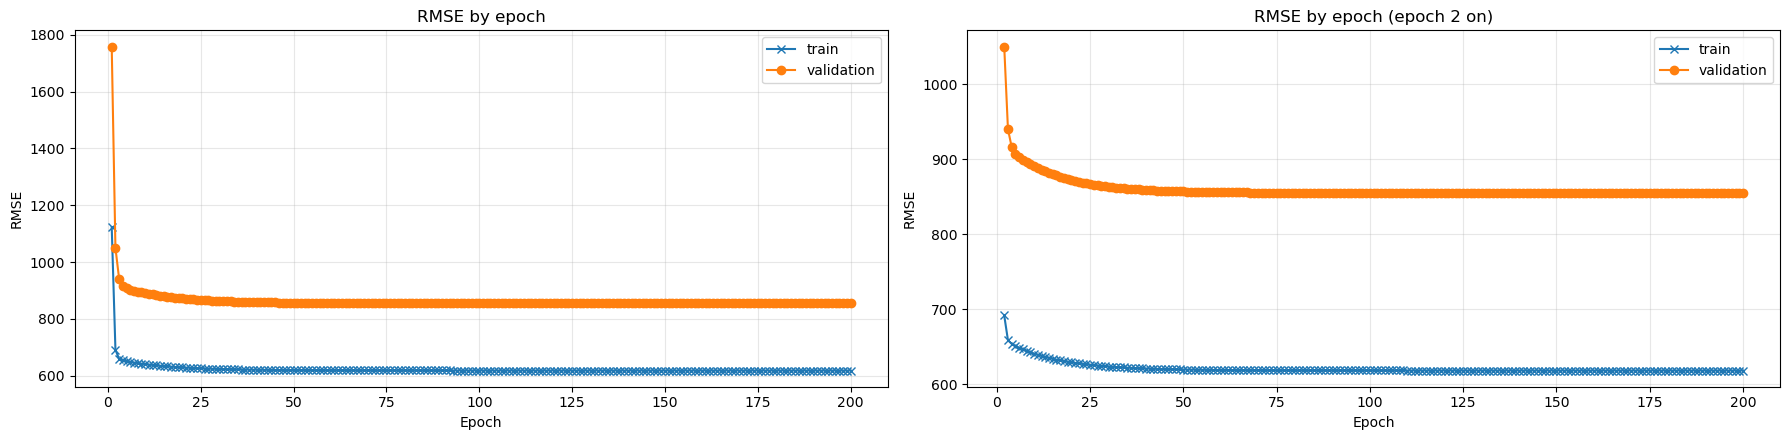

In [39]:
fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(18, 4.5))

# left: every epoch. right: from epoch 2 on, where the two lines can be told apart
for ax, scores, title in [
	(ax_all, epoch_scores, "RMSE by epoch"),
	(ax_zoom, epoch_scores.loc[2:], "RMSE by epoch (epoch 2 on)"),
]:
	ax.plot(scores.index, scores["train RMSE"], "x-", color="C0", label="train")
	ax.plot(scores.index, scores["val RMSE"], "o-", color="C1", label="validation")
	ax.set_xlabel("Epoch")
	ax.set_ylabel("RMSE")
	ax.set_title(title)
	ax.grid(alpha=0.3)
	ax.legend()

plt.tight_layout()
plt.show()

**Training and validation loss by epoch.** The curve uses the last fold: 553 training rows and 31 validation rows. Most of the learning happens in the first few epochs. From epoch 1 to epoch 2, training RMSE falls from 1123.1825 to 691.9606 and validation RMSE from 1758.5646 to 1050.3682, and by epoch 5 they are at 651.3821 and 907.7857. After that both lines keep falling slowly: 623.9546 and 863.5498 at epoch 30, then 618.6506 and 855.3751 at epoch 100. From there they are flat (618.5994 and 855.3423 at epoch 200). Validation RMSE never turns back up while training RMSE falls: its lowest listed value is 855.3410 at epoch 150, and it is 855.3423 at epoch 200. So more epochs do not overfit. Validation RMSE stays far above training RMSE at every epoch, the same gap the folds show, so that gap is not caused by training too long. The model converges within about 100 epochs, in line with the final model stopping by itself after 155.

# Reproducibility
No step depends on an unseeded random draw. The folds are time-ordered, so they involve no shuffle, and every `SGDRegressor` uses `random_state=42`. Running the notebook again from the top gives the same numbers.